# Age at the time of the photo — Echooo AI take-home (candidate 0167)

Given a Wikipedia page of a person, find a usable photo and estimate **how old the person was when the photo was taken**
(age bracket + estimated age). This notebook contains the whole project, end to end, and runs on a **CPU** machine (VS Code / Jupyter).

| Stage | What | Network | Typical CPU time |
|---|---|---|---|
| 1 | Candidate people from Wikidata | Wikidata | ~10 min (skipped if `data/candidates.csv` exists) |
| 2 | Lead image + Commons photo date + true age/bracket labels | Wikipedia, Commons | ~25 min (skipped if `data/labelled.csv` exists) |
| 3 | Balanced subset, download photos, face filter, train/val/test split | Wikimedia | ~20 min (skipped if `data/final.csv` exists) |
| 4 | **CV approach**: pretrained ViT age model, zero-shot + linear probe | Hugging Face (model download) | ~5-15 min |
| 5 | **LLM approach**: vision LLM on the *same* test photos | Gemini API (free tier) or a local model | depends on quota |
| 6 | Evaluation: accuracy, confusion matrices, MAE, calibration, paired tests | - | seconds |
| 7 | Build the live API (FastAPI + Docker), tests, parity check, deploy | Hugging Face Spaces | ~15 min |

Each of stages 1-3 has: an explanation, small documented code cells, **self-checks** (hand-made cases that must pass), an optional **live check** on a few real items (`LIVE_CHECKS`), and a summary with plots.

**Already ran stages 1-3 on Colab?** Copy the Colab `data/` folder (at least `final.csv`, `labelled.csv`, `faces/`, `images/`, and `cv_features.npz` / `step2_all.csv` / `step3_all.csv` if present) into the folder next to this notebook. The notebook detects it and skips the slow stages.

**Rules followed:** all data is collected from Wikipedia / Wikidata / Wikimedia Commons; no ready-made labelled face-age dataset is used for training or testing. Pretrained models are named in the README. No API key is stored in this notebook: keys are read from the environment or typed into a hidden prompt.

In [8]:
%pip install -q pandas numpy requests scikit-learn scipy matplotlib opencv-python-headless pillow tqdm ipywidgets torch transformers accelerate google-genai fastapi httpx pytest huggingface_hub
# CPU-only torch on Linux/Windows (much smaller download): %pip install -q torch --index-url https://download.pytorch.org/whl/cpu

## 0. Configuration
Edit this cell only. **Set `CONTACT` to your real email**: Wikimedia's User-Agent policy requires it, and generic clients on shared IPs get rate-limited.

In [9]:
CONTACT = "123muhammadshahzad26@gmail.com"        # <- CHANGE: real email (Wikimedia User-Agent policy)

# LLM approach (stage 5). "gemini" = Google AI Studio free tier, "qwen_local" = small open model on CPU (slow), "none" = skip
LLM_BACKEND = "gemini"
LLM_TEST_LIMIT = 120                   # test photos sent to the LLM, balanced across brackets (None = all test photos)
GEMINI_MODEL = "gemini-3.1-flash-lite" # check with list_gemini_models() in stage 5; free-tier model names change often
GEMINI_SLEEP = 6.0                     # seconds between calls (free-tier requests/minute limit)
QWEN_ID = "Qwen/Qwen2.5-VL-3B-Instruct"  # only for LLM_BACKEND = "qwen_local" (needs ~8 GB RAM, ~30-90 s per photo on CPU)

# Small live checks of stages 1-3 against Wikidata / Wikipedia / Commons (a few requests each, nothing is overwritten)
LIVE_CHECKS = True

# Data stages: set a flag to True to redo that stage even if its output file already exists
RERUN = {"candidates": False, "labels": False, "photos": False, "cv": False, "llm": False}

SEED = 42

In [10]:
import os, re, io, json, glob, math, time, html, shutil, getpass, calendar, threading, warnings
import datetime as dt
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import requests
import cv2
from PIL import Image
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as IPyImage

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
np.random.seed(SEED)

for d in ["data", "data/images", "data/faces", "models", "results"]:
    Path(d).mkdir(parents=True, exist_ok=True)

UA = {"User-Agent": f"EchoooAgeAssignment/0.2 (take-home project; {CONTACT}) python-requests"}

BRACKETS = ["Under 18", "18-24", "25-34", "35-44", "45-54", "55+"]
BRACKET_EDGES = [(0, 18), (18, 25), (25, 35), (35, 45), (45, 55), (55, 100)]  # [lo, hi)


def bracket_of_age(age):
    for name, (lo, hi) in zip(BRACKETS, BRACKET_EDGES):
        if lo <= age < hi:
            return name
    return BRACKETS[-1]


def clamp_age(age, bracket):
    """Keep the exact age consistent with the predicted bracket (same rule as the live API)."""
    lo, hi = BRACKET_EDGES[BRACKETS.index(bracket)]
    return int(round(min(max(float(age), lo), hi - 1)))


def need_contact():
    if "@" not in CONTACT or CONTACT.startswith("your.real"):
        raise SystemExit("Set CONTACT in the configuration cell to your real email, then re-run from there.")


def status():
    rows = [("data/candidates.csv", Path("data/candidates.csv").exists()),
            ("data/labelled.csv", Path("data/labelled.csv").exists()),
            ("data/final.csv", Path("data/final.csv").exists()),
            ("data/images/*.jpg", len(glob.glob("data/images/*.jpg"))),
            ("data/faces/*.jpg", len(glob.glob("data/faces/*.jpg"))),
            ("data/yunet.onnx", Path("data/yunet.onnx").exists()),
            ("models/cv_probe.npz", Path("models/cv_probe.npz").exists()),
            ("results/preds_*.csv", len(glob.glob("results/preds_*.csv")))]
    print(pd.DataFrame(rows, columns=["file", "exists / count"]).to_string(index=False))


status()

               file exists / count
data/candidates.csv          False
  data/labelled.csv          False
     data/final.csv          False
  data/images/*.jpg              0
   data/faces/*.jpg              0
    data/yunet.onnx          False
models/cv_probe.npz          False
results/preds_*.csv              0


## 1. Candidate people (Wikidata)
**Goal:** a pool of people who have (a) an English Wikipedia article, (b) a Wikidata image and (c) a birth date with **day precision**, so the age arithmetic later is exact.

**Sampling grid:** 8 occupations (actor, singer, footballer, basketball player, politician, writer, athlete, film director) x 7 birth decades (1940s-2000s), up to 200 people per cell and 350 for the 1990s/2000s, because "Under 18" photos are the rarest and come from young people.

**Known limitations (they go in the README):** Wikidata cannot order results randomly without timing out, so sampling *inside* each occupation/decade cell is not random; the pool is notable people with freely licensed photos. If a cell times out it is retried as two 5-year queries.

In [11]:
# --- configuration of the sampling grid and the SPARQL query
SPARQL_URL = "https://query.wikidata.org/sparql"
HEADERS = {**UA, "Accept": "application/sparql-results+json"}

OCCUPATIONS = {
    "actor": "Q33999",
    "singer": "Q177220",
    "footballer": "Q937857",
    "basketball_player": "Q3665646",
    "politician": "Q82955",
    "writer": "Q36180",
    "athlete": "Q2066131",
    "film_director": "Q2526255",
}

# (start_year, end_year_exclusive)
DECADES = [(1940, 1950), (1950, 1960), (1960, 1970), (1970, 1980),
           (1980, 1990), (1990, 2000), (2000, 2010)]

# Rows per (decade, occupation) cell. Young decades get more to find Under-18 photos.
LIMIT_DEFAULT = 200
LIMIT_YOUNG = 350  # birth decades 1990s and 2000s

QUERY = """
SELECT DISTINCT ?item ?itemLabel ?dob ?image ?title WHERE {{
  ?item wdt:P31 wd:Q5 ;
        wdt:P106 wd:{occ} ;
        wdt:P18 ?image ;
        p:P569/psv:P569 ?dobNode .
  ?dobNode wikibase:timeValue ?dob ;
           wikibase:timePrecision 11 .
  FILTER(YEAR(?dob) >= {y0} && YEAR(?dob) < {y1})
  ?article schema:about ?item ;
           schema:isPartOf <https://en.wikipedia.org/> ;
           schema:name ?title .
  SERVICE wikibase:label {{ bd:serviceParam wikibase:language "en". }}
}}
LIMIT {limit}
"""

In [12]:
# --- query runner, row builder, cleaning and the full collection routine
def run_query(occ_qid, y0, y1, limit, retries=3):
    q = QUERY.format(occ=occ_qid, y0=y0, y1=y1, limit=limit)
    for attempt in range(retries):
        try:
            r = requests.get(SPARQL_URL, params={"query": q}, headers=HEADERS, timeout=90)
            if r.status_code == 200:
                return r.json()["results"]["bindings"]
            print(f"  HTTP {r.status_code}, retry {attempt + 1}")
        except requests.RequestException as e:
            print(f"  error: {e}, retry {attempt + 1}")
        time.sleep(5 * (attempt + 1))
    return []


def binding_to_row(b, occ_name):
    """One Wikidata SPARQL result row -> one candidate record."""
    return {
        "qid": b["item"]["value"].rsplit("/", 1)[-1],
        "name": b.get("itemLabel", {}).get("value", ""),
        "wiki_title": b["title"]["value"],
        "wiki_url": "https://en.wikipedia.org/wiki/" + b["title"]["value"].replace(" ", "_"),
        "birth_date": b["dob"]["value"][:10],
        "occupation": occ_name,
        "p18_file": b["image"]["value"].rsplit("/", 1)[-1],
    }


def clean_candidates(rows, target=5000, seed=42):
    """Dedupe by person, drop unlabelled / implausible rows, balance by birth decade, shuffle."""
    df = pd.DataFrame(rows)
    print(f"\nRaw rows: {len(df)}")
    # A person can appear under several occupations: keep the first, dedupe by QID.
    df = df.drop_duplicates(subset="qid")
    # Drop rows whose label is just a QID (no English label) or whose birth year looks invalid.
    df = df[~df["name"].str.match(r"^Q\d+$")].copy()
    df["birth_year"] = df["birth_date"].str[:4].astype(int)
    df = df[(df["birth_year"] >= 1940) & (df["birth_year"] <= 2009)].copy()
    print(f"After dedupe/cleaning: {len(df)}")
    # Downsample to the target while keeping the birth-decade balance.
    if len(df) > target:
        decade = (df["birth_year"] // 10) * 10
        per_decade = target // decade.nunique()
        df = pd.concat([g.sample(min(len(g), per_decade), random_state=seed) for _, g in df.groupby(decade)])
    return df.sample(frac=1, random_state=seed).reset_index(drop=True)


def collect_candidates(out_path="data/candidates.csv", target=5000, seed=42):
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    rows = []
    for occ_name, occ_qid in OCCUPATIONS.items():
        for (y0, y1) in DECADES:
            limit = LIMIT_YOUNG if y0 >= 1990 else LIMIT_DEFAULT
            print(f"Querying {occ_name} born {y0}-{y1 - 1} (limit {limit})")
            bindings = run_query(occ_qid, y0, y1, limit)
            if not bindings:  # query-service timeout: retry as two smaller 5-year queries
                mid = (y0 + y1) // 2
                bindings = (run_query(occ_qid, y0, mid, limit // 2)
                            + run_query(occ_qid, mid, y1, limit // 2))
            for b in bindings:
                rows.append(binding_to_row(b, occ_name))
            time.sleep(1.5)  # be polite to the query service

    df = clean_candidates(rows, target, seed)
    df.to_csv(out_path, index=False)

    print(f"\nSaved {len(df)} candidates to {out_path}")
    print("\nBy occupation:\n", df["occupation"].value_counts().to_string())
    print("\nBy birth decade:\n", ((df["birth_year"] // 10) * 10).value_counts().sort_index().to_string())

In [13]:
# Self-check of the pure logic (no network): a canned Wikidata answer and a synthetic pool
_canned = {"item": {"value": "http://www.wikidata.org/entity/Q42"}, "itemLabel": {"value": "Douglas Adams"},
           "title": {"value": "Douglas Adams"}, "dob": {"value": "1952-03-11T00:00:00Z"},
           "image": {"value": "http://commons.wikimedia.org/wiki/Special:FilePath/Douglas%20adams.jpg"}}
_row = binding_to_row(_canned, "writer")
assert _row["qid"] == "Q42" and _row["birth_date"] == "1952-03-11" and _row["wiki_url"].endswith("Douglas_Adams")
_rng = np.random.RandomState(0)
_pool = [dict(qid=f"Q{i % 2500}", name=("Q99" if i == 5 else f"P{i}"), wiki_title=f"P{i}", wiki_url="u",
              birth_date=f"{_rng.randint(1930, 2015)}-01-02", occupation="actor", p18_file="f.jpg") for i in range(3000)]
_c = clean_candidates(_pool, target=1000, seed=1)
assert _c["qid"].is_unique and _c["birth_year"].between(1940, 2009).all() and len(_c) <= 1000
assert ((_c["birth_year"] // 10) * 10).nunique() == 7, "all 7 birth decades must be present"
print("stage 1 self-checks passed: duplicates removed, unlabelled people dropped, birth years 1940-2009, decades balanced")


Raw rows: 3000
After dedupe/cleaning: 2035
stage 1 self-checks passed: duplicates removed, unlabelled people dropped, birth years 1940-2009, decades balanced


In [14]:
# Optional live check: ask Wikidata for 5 actors born in the 1990s (one small request)
if LIVE_CHECKS:
    need_contact()
    _b = run_query(OCCUPATIONS["actor"], 1990, 2000, 5)
    if _b:
        print(f"Wikidata answered with {len(_b)} rows. First 3 candidates:")
        display(pd.DataFrame([binding_to_row(x, "actor") for x in _b[:3]]))
    else:
        print("No answer from Wikidata (offline or throttled?). Stage 1 would retry; see the messages above.")
else:
    print("LIVE_CHECKS = False -> skipped")

Wikidata answered with 5 rows. First 3 candidates:


,qid,name,wiki_title,wiki_url,birth_date,occupation,p18_file
0,Q54828865,Sophia Everest,Sophia Everest,https://en.wikipedia.org/wiki/Sophia_Everest,1992-04-30,actor,Sophia%20Everest.jpg
1,Q62070240,Jordan Claire Robbins,Jordan Claire Robbins,https://en.wikipedia.org/wiki/Jordan_Claire_Robbins,1990-01-24,actor,Jordan%20Claire%20Robbins%20at%2082nd%20Venice%20International%20F...
2,Q6162161,Jason Canela,Jason Canela,https://en.wikipedia.org/wiki/Jason_Canela,1992-04-25,actor,Jason%20Canela.jpg


In [15]:
if RERUN["candidates"] or not Path("data/candidates.csv").exists():
    need_contact()
    collect_candidates()
else:
    print("data/candidates.csv exists -> collection skipped (RERUN['candidates'] = True to redo it)")
candidates = pd.read_csv("data/candidates.csv")
print(len(candidates), "candidate people")
display(pd.concat([candidates["occupation"].value_counts().rename("people by occupation"),
                   ((candidates["birth_date"].str[:4].astype(int) // 10) * 10).value_counts().sort_index().rename("people by birth decade")], axis=1).fillna("").astype(str))
display(candidates.head(3))

Querying actor born 1940-1949 (limit 200)
Querying actor born 1950-1959 (limit 200)
Querying actor born 1960-1969 (limit 200)
Querying actor born 1970-1979 (limit 200)
Querying actor born 1980-1989 (limit 200)
Querying actor born 1990-1999 (limit 350)
Querying actor born 2000-2009 (limit 350)
Querying singer born 1940-1949 (limit 200)
Querying singer born 1950-1959 (limit 200)
Querying singer born 1960-1969 (limit 200)
Querying singer born 1970-1979 (limit 200)
Querying singer born 1980-1989 (limit 200)
Querying singer born 1990-1999 (limit 350)
Querying singer born 2000-2009 (limit 350)
Querying footballer born 1940-1949 (limit 200)
Querying footballer born 1950-1959 (limit 200)
Querying footballer born 1960-1969 (limit 200)
Querying footballer born 1970-1979 (limit 200)
Querying footballer born 1980-1989 (limit 200)
Querying footballer born 1990-1999 (limit 350)
Querying footballer born 2000-2009 (limit 350)
Querying basketball_player born 1940-1949 (limit 200)
Querying basketball_pl

,people by occupation,people by birth decade
basketball_player,742.0,
singer,722.0,
actor,699.0,
footballer,678.0,
athlete,574.0,
politician,562.0,
writer,525.0,
film_director,496.0,
1940,,714.0
1950,,714.0


,qid,name,wiki_title,wiki_url,birth_date,occupation,p18_file,birth_year
0,Q225193,Vasily Alekseyev,Vasily Alekseyev,https://en.wikipedia.org/wiki/Vasily_Alekseyev,1942-01-07,athlete,Vasily%20Alekseyev%201970.jpg,1942
1,Q58592,Daniel Brühl,Daniel Brühl,https://en.wikipedia.org/wiki/Daniel_Brühl,1978-06-16,film_director,MJK%2068238%20Daniel%20Br%C3%BChl%20%28Berlinale%202020%29.jpg,1978
2,Q522759,André Schubert,André Schubert,https://en.wikipedia.org/wiki/André_Schubert,1971-07-24,footballer,Andr%C3%A9%20Schubert%202012.jpg,1971


## 2. Lead image, photo date and the true age bracket
For every candidate: Wikipedia lead image -> its Wikimedia Commons record -> `DateTimeOriginal` (camera EXIF, or the date the uploader typed).
**True age** = completed years between the Wikidata birth date and the photo date, then mapped to a bracket (`Under 18 | 18-24 | 25-34 | 35-44 | 45-54 | 55+`).

| Photo date | Rule |
|---|---|
| day precision (`2016-05-03`, `3 May 2016`, with or without a time) | exact age; kept |
| month or year precision (`March 2012`, `1985`) | youngest and oldest possible age are computed; kept **only if both are in the same bracket** (exact age not used for MAE) |
| circa / before / after / decade / range / `10/6/2006` (ambiguous) | dropped (`unparseable_date`) |
| text says *upload*, *scan* or *publication* date | dropped: not a capture date |
| `Taken on 6 April 2006`, `(according to Exif data)` | cleaned, then parsed (second pass) |

Other drops: no lead image, not on Commons (local fair-use file), not JPEG/PNG, shorter than 200 px, no date, photo before birth, implausible age. Every Wikipedia/Commons answer is cached in `data/cache_*.json`, and HTTP 429 answers are retried with a long back-off, so a re-run does not repeat finished work.

In [16]:
# --- constants and the age arithmetic
WP = "https://en.wikipedia.org/w/api.php"
CM = "https://commons.wikimedia.org/w/api.php"
TODAY = dt.date.today()



def bracket(age):
    if age < 18: return "Under 18"
    if age <= 24: return "18-24"
    if age <= 34: return "25-34"
    if age <= 44: return "35-44"
    if age <= 54: return "45-54"
    return "55+"


def age_on(birth, d):
    return d.year - birth.year - ((d.month, d.day) < (birth.month, birth.day))

In [17]:
# ------------------------------------------------------------------ API helpers
def api(url, params, retries=5):
    params = {**params, "format": "json", "formatversion": 2}
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, headers=UA, timeout=60)
            if r.status_code == 200:
                return r.json()
            if r.status_code == 429:  # rate limited: wait much longer each time
                wait = 20 * (attempt + 1)
                print(f"  HTTP 429, waiting {wait}s")
                time.sleep(wait)
                continue
            print(f"  HTTP {r.status_code}, retry {attempt + 1}")
        except requests.RequestException as e:
            print(f"  error: {e}, retry {attempt + 1}")
        time.sleep(3 * (attempt + 1))
    return None


def resolve(title, norm, redir):
    t = norm.get(title, title)
    return redir.get(t, t)


def fetch_lead_images(titles):
    """Wikipedia 'page image' per title -> file name (without 'File:') or None."""
    out = {}
    for i in range(0, len(titles), 50):
        batch = titles[i:i + 50]
        data = api(WP, {"action": "query", "titles": "|".join(batch),
                        "prop": "pageimages", "piprop": "name", "redirects": 1})
        if data is None:
            for t in batch: out[t] = "API_ERROR"
            continue
        q = data.get("query", {})
        norm = {n["from"]: n["to"] for n in q.get("normalized", [])}
        redir = {r["from"]: r["to"] for r in q.get("redirects", [])}
        pages = {p["title"]: p for p in q.get("pages", [])}
        for t in batch:
            p = pages.get(resolve(t, norm, redir))
            out[t] = p.get("pageimage") if p else None
        print(f"  lead images: {min(i + 50, len(titles))}/{len(titles)}")
        time.sleep(1.5)
    return out


def meta_value(md, key):
    """Commons returns extmetadata as {} / [] / {key: {"value": ...}}; be tolerant."""
    v = md.get(key) if isinstance(md, dict) else None
    return v.get("value") if isinstance(v, dict) else None


def load_cache(path):
    import json
    try:
        with open(path) as f:
            return json.load(f)
    except (OSError, ValueError):
        return {}


def save_cache(path, d):
    import json
    with open(path, "w") as f:  # API errors are not cached, so a rerun retries them
        json.dump({k: v for k, v in d.items() if v != "API_ERROR"}, f)


def fetch_commons_info(files):
    """Commons imageinfo per file name -> dict (url, size, mime, date, license) or None."""
    out = {}
    for i in range(0, len(files), 50):
        batch = files[i:i + 50]
        titles = ["File:" + f.replace("_", " ") for f in batch]
        data = api(CM, {"action": "query", "titles": "|".join(titles), "prop": "imageinfo",
                        "iiprop": "url|size|mime|extmetadata", "iiurlwidth": 960,
                        "iiextmetadatafilter": "DateTimeOriginal|LicenseShortName|Artist",
                        "redirects": 1})
        if data is None:
            for f in batch: out[f] = "API_ERROR"
            continue
        q = data.get("query", {})
        norm = {n["from"]: n["to"] for n in q.get("normalized", [])}
        redir = {r["from"]: r["to"] for r in q.get("redirects", [])}
        pages = {p["title"]: p for p in q.get("pages", [])}
        for f, t in zip(batch, titles):
            p = pages.get(resolve(t, norm, redir))
            if not p or p.get("missing") or not p.get("imageinfo"):
                out[f] = None
                continue
            ii = p["imageinfo"][0]
            md = ii.get("extmetadata")
            out[f] = {
                "image_url": ii.get("url"),
                "thumb_url": ii.get("thumburl"),
                "file_page": ii.get("descriptionurl"),
                "width": ii.get("width"), "height": ii.get("height"),
                "mime": ii.get("mime"),
                "raw_date": meta_value(md, "DateTimeOriginal"),
                "license": meta_value(md, "LicenseShortName"),
            }
        print(f"  commons info: {min(i + 50, len(files))}/{len(files)}")
        time.sleep(1.5)
    return out

In [18]:
# ------------------------------------------------------------------ date parsing
MONTHS = {m.lower(): i for i, m in enumerate(calendar.month_name) if m}
MONTHS.update({m.lower(): i for i, m in enumerate(calendar.month_abbr) if m})
BAD = re.compile(r"\b(circa|ca|c|about|approx\w*|around|before|after|between|early|late|"
                 r"mid|or|to|and|unknown|undated)\b|[?~/\u2013\u2014]", re.I)


def parse_photo_date(raw):
    """Return (date_lo, date_hi, precision) or (None, None, reason)."""
    if not raw:
        return None, None, "no_photo_date"
    m = re.search(r'datetime="([^"]+)"', raw)
    s = m.group(1) if m else html.unescape(re.sub(r"<[^>]+>", " ", raw))
    s = re.sub(r"\s+", " ", s).strip().rstrip(".")
    # the text says the date is NOT the capture date (upload / scan / publication date)
    if re.search(r"\b(upload\w*|scan\w*|publi\w*|clipping|stamp\w*)\b", s, re.I):
        return None, None, "unparseable_date"
    if (BAD.search(s) or re.search(r"\d{4}s", s)
            or len(re.findall(r"\b\d{4}\b", s)) != 1):
        return None, None, "unparseable_date"

    y = mo = d = None
    if (m := re.match(r"^(\d{4})[-:](\d{2})[-:](\d{2})(?:[T ].*)?$", s)):
        y, mo, d = map(int, m.groups())
    elif (m := re.match(r"^(\d{4})-(\d{2})$", s)):
        y, mo = map(int, m.groups())
    elif (m := re.match(r"^(\d{4})$", s)):
        y = int(m.group(1))
    elif (m := re.match(r"^(\d{1,2}) ([A-Za-z]+),? (\d{4})(?: .*)?$", s)) and m.group(2).lower() in MONTHS:
        d, mo, y = int(m.group(1)), MONTHS[m.group(2).lower()], int(m.group(3))
    elif (m := re.match(r"^([A-Za-z]+) (\d{1,2}),? (\d{4})(?: .*)?$", s)) and m.group(1).lower() in MONTHS:
        mo, d, y = MONTHS[m.group(1).lower()], int(m.group(2)), int(m.group(3))
    elif (m := re.match(r"^([A-Za-z]+),? (\d{4})$", s)) and m.group(1).lower() in MONTHS:
        mo, y = MONTHS[m.group(1).lower()], int(m.group(2))
    else:
        return None, None, "unparseable_date"

    try:
        if d:
            lo = hi = dt.date(y, mo, d); prec = "day"
        elif mo:
            lo = dt.date(y, mo, 1)
            hi = dt.date(y, mo, calendar.monthrange(y, mo)[1]); prec = "month"
        else:
            lo, hi = dt.date(y, 1, 1), dt.date(y, 12, 31); prec = "year"
    except ValueError:
        return None, None, "unparseable_date"
    if y < 1900 or lo > TODAY:
        return None, None, "implausible_date"
    return lo, min(hi, TODAY), prec


def clean_raw(raw):
    """Second-pass cleaning for strings like 'Taken on 6 April 2006' or
    '20 September 2025 (according to Exif data)'. Returns None if the date is
    explicitly not a capture date (upload / scan / publication date)."""
    s = html.unescape(re.sub(r"<[^>]+>", " ", str(raw)))
    s = re.sub(r"\s+", " ", s).strip()
    if re.search(r"\([^)]*(upload|scan|publi)", s, re.I):
        return None
    s = re.sub(r"\([^)]*\)", " ", s)
    s = re.sub(r"^(taken|photographed|created)( on)?\s+", "", s, flags=re.I)
    s = re.sub(r",\s*(?=\d{1,2}:\d{2})", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def label(birth, lo, hi, prec):
    """Return (ok, reason_or_None, bracket, age_int, age_exact)."""
    if hi < birth:
        return False, "photo_before_birth", None, None, None
    lo = max(lo, birth)
    a_lo, a_hi = age_on(birth, lo), age_on(birth, hi)
    if a_hi > 100:
        return False, "implausible_age", None, None, None
    if bracket(a_lo) != bracket(a_hi):
        return False, "ambiguous_bracket", None, None, None
    exact = round((lo - birth).days / 365.25, 2) if prec == "day" else None
    return True, None, bracket(a_lo), a_lo, exact

In [19]:
# --- the labelling logic for a table of candidates (no network inside)
def label_rows(df, lead, info):
    """Pure labelling logic (no network): candidates + {wiki_title: lead file} + {file: Commons record}
    -> one row per candidate with photo date, true age, bracket and a drop_reason ('KEPT' if usable)."""
    df = df.copy()
    df["lead_file"] = df["wiki_title"].map(lead)
    recs = []
    for _, r in df.iterrows():
        rec = r.to_dict()
        rec.update({k: None for k in ["image_url", "thumb_url", "file_page", "width", "height",
                                      "mime", "license", "raw_date", "photo_date",
                                      "date_precision", "age_bracket", "age_int", "age_exact"]})
        rec["drop_reason"] = None
        f = r["lead_file"]
        if f == "API_ERROR":
            rec["drop_reason"] = "wikipedia_api_error"
        elif pd.isna(f):
            rec["drop_reason"] = "no_lead_image"
        else:
            ci = info.get(f)
            if ci == "API_ERROR":
                rec["drop_reason"] = "commons_api_error"
            elif ci is None:
                rec["drop_reason"] = "not_on_commons"  # e.g. local fair-use file
            else:
                rec.update({k: ci[k] for k in ["image_url", "thumb_url", "file_page", "width",
                                               "height", "mime", "license"]})
                rec["raw_date"] = ci["raw_date"]
                if ci["mime"] not in ("image/jpeg", "image/png"):
                    rec["drop_reason"] = "bad_mime"
                elif (ci["width"] or 0) < 200 or (ci["height"] or 0) < 200:
                    rec["drop_reason"] = "too_small"
                else:
                    lo, hi, prec = parse_photo_date(ci["raw_date"])
                    if lo is None and prec == "unparseable_date":
                        cleaned = clean_raw(ci["raw_date"])
                        if cleaned:
                            lo, hi, prec = parse_photo_date(cleaned)
                    if lo is None:
                        rec["drop_reason"] = prec  # prec holds the reason here
                    else:
                        birth = dt.date.fromisoformat(r["birth_date"])
                        ok, why, br, age, exact = label(birth, lo, hi, prec)
                        if not ok:
                            rec["drop_reason"] = why
                        else:
                            rec.update({"photo_date": lo.isoformat() if prec == "day" else
                                        f"{lo.isoformat()}..{hi.isoformat()}",
                                        "date_precision": prec, "age_bracket": br,
                                        "age_int": age, "age_exact": exact})
        if rec["drop_reason"] is None:
            rec["drop_reason"] = "KEPT"
        recs.append(rec)

    return pd.DataFrame(recs)

In [20]:
# --- the full stage: fetch (with caches) -> label -> save -> print the funnel
def label_photos(inp="data/candidates.csv", out_all="data/step2_all.csv", out_ok="data/labelled.csv"):
    df = pd.read_csv(inp)
    print(f"Candidates in: {len(df)}")

    lead = load_cache("data/cache_lead.json")
    missing = [t for t in df["wiki_title"] if t not in lead]
    print(f"Fetching Wikipedia lead images... ({len(missing)} not cached)")
    lead.update(fetch_lead_images(missing))
    save_cache("data/cache_lead.json", lead)
    df["lead_file"] = df["wiki_title"].map(lead)

    files = sorted({f for f in df["lead_file"].dropna().unique() if f != "API_ERROR"})
    info = load_cache("data/cache_commons.json")
    missing_f = [f for f in files if f not in info]
    print(f"Fetching Commons info for {len(missing_f)} of {len(files)} unique files (rest cached)...")
    info.update(fetch_commons_info(missing_f))
    save_cache("data/cache_commons.json", info)

    res = label_rows(df, lead, info)
    res.to_csv(out_all, index=False)
    ok = res[res["drop_reason"] == "KEPT"].copy()
    ok.to_csv(out_ok, index=False)

    print("\n=== Funnel (copy into README) ===")
    print(res["drop_reason"].value_counts().to_string())
    print(f"\nKept {len(ok)} of {len(res)} candidates")
    print("\nKept by bracket:\n", ok["age_bracket"].value_counts().reindex(BRACKETS).to_string())
    print("\nKept by date precision:\n", ok["date_precision"].value_counts().to_string())

In [21]:
# Self-check: 19 hand-made cases through the real labelling code (canned Commons records, no network)
def _rec(raw="2010-05-09", mime="image/jpeg", w=800, h=900):
    return {"image_url": "u", "thumb_url": "t", "file_page": "p", "width": w, "height": h, "mime": mime, "license": "CC", "raw_date": raw}

_cases = [  # (name, birth date, lead file, Commons record, expected drop_reason, expected bracket, expected age)
    ("day exact",          "1990-05-10", "A", _rec(raw="2010-05-09"),             "KEPT", "18-24", 19),
    ("on the birthday",    "1990-05-10", "B", _rec(raw="2010-05-10"),             "KEPT", "18-24", 20),
    ("month, certain",     "1990-05-10", "C", _rec(raw="2000-05"),                "KEPT", "Under 18", 9),
    ("month straddles",    "1990-05-20", "D", _rec(raw="2008-05"),                "ambiguous_bracket", None, None),
    ("year straddles",     "1990-05-10", "E", _rec(raw="2015"),                   "ambiguous_bracket", None, None),
    ("photo before birth", "1990-05-10", "F", _rec(raw="1980-01-01"),             "photo_before_birth", None, None),
    ("no lead image",      "1990-05-10", None, None,                              "no_lead_image", None, None),
    ("Wikipedia error",    "1990-05-10", "API_ERROR", None,                       "wikipedia_api_error", None, None),
    ("not on Commons",     "1990-05-10", "G", None,                               "not_on_commons", None, None),
    ("Commons error",      "1990-05-10", "H", "API_ERROR",                        "commons_api_error", None, None),
    ("SVG file",           "1990-05-10", "I", _rec(mime="image/svg+xml"),         "bad_mime", None, None),
    ("too small",          "1990-05-10", "J", _rec(w=150),                        "too_small", None, None),
    ("circa",              "1990-05-10", "K", _rec(raw="circa 2005"),             "unparseable_date", None, None),
    ("no date",            "1990-05-10", "L", _rec(raw=None),                     "no_photo_date", None, None),
    ("'Taken on' (rescued)", "1990-05-10", "M", _rec(raw="Taken on 6 April 2012"), "KEPT", "18-24", 21),
    ("upload date",        "1990-05-10", "N", _rec(raw="23 April 2012 (original upload date)"), "unparseable_date", None, None),
    ("55+",                "1950-01-01", "O", _rec(raw="2010-06-01"),             "KEPT", "55+", 60),
    ("day before 35th bday", "1980-06-15", "P", _rec(raw="2015-06-14"),          "KEPT", "25-34", 34),
    ("on the 35th birthday", "1980-06-15", "Q", _rec(raw="2015-06-15"),          "KEPT", "35-44", 35),
]
_df = pd.DataFrame({"qid": [f"T{i}" for i in range(len(_cases))], "wiki_title": [c[0] for c in _cases], "birth_date": [c[1] for c in _cases]})
_res = label_rows(_df, {c[0]: c[2] for c in _cases}, {c[2]: c[3] for c in _cases if c[2] not in (None, "API_ERROR")})
_out = []
for c, (_, r) in zip(_cases, _res.iterrows()):
    ok = r["drop_reason"] == c[4] and (c[5] is None or (r["age_bracket"] == c[5] and int(r["age_int"]) == c[6]))
    _out.append({"case": c[0], "got": r["drop_reason"], "bracket": r["age_bracket"], "age": r["age_int"], "ok": "OK" if ok else "WRONG"})
display(pd.DataFrame(_out))
assert all(o["ok"] == "OK" for o in _out), "labelling self-check failed"
print("stage 2 self-checks passed: 19/19")

,case,got,bracket,age,ok
0,day exact,KEPT,18-24,19.0,OK
1,on the birthday,KEPT,18-24,20.0,OK
2,"month, certain",KEPT,Under 18,9.0,OK
3,month straddles,ambiguous_bracket,None,NaN,OK
4,year straddles,ambiguous_bracket,None,NaN,OK
5,photo before birth,photo_before_birth,None,NaN,OK
6,no lead image,no_lead_image,None,NaN,OK
7,Wikipedia error,wikipedia_api_error,None,NaN,OK
8,not on Commons,not_on_commons,None,NaN,OK
9,Commons error,commons_api_error,None,NaN,OK


stage 2 self-checks passed: 19/19


In [22]:
# Optional live check: run the REAL fetch + labelling code on 12 random candidates (no files are written)
if LIVE_CHECKS:
    need_contact()
    _cand = pd.read_csv("data/candidates.csv").sample(12, random_state=1).reset_index(drop=True)
    _lead = fetch_lead_images(_cand["wiki_title"].tolist())
    _info = fetch_commons_info(sorted({f for f in _lead.values() if f and f != "API_ERROR"}))
    display(label_rows(_cand, _lead, _info)[["name", "birth_date", "lead_file", "raw_date", "photo_date", "age_bracket", "age_exact", "drop_reason"]])
else:
    print("LIVE_CHECKS = False -> skipped")

  lead images: 12/12
  commons info: 10/10


,name,birth_date,lead_file,raw_date,photo_date,age_bracket,age_exact,drop_reason
0,Marc Alaimo,1942-05-05,Marc_Alaimo.jpg,2011-10-25 00:19,2011-10-25,55+,69.47,KEPT
1,Sam Bowie,1961-03-17,Sam_Bowie_during_1985_NBA_Playoffs.jpg,1985-05-08,1985-05-08,18-24,24.14,KEPT
2,Baek Seo-yi,1992-08-03,Baek_Seo-yi_in_TenAsia_Interview_in_2016_(1).jpg,2016-08-10,2016-08-10,18-24,24.02,KEPT
3,Lil' Kim,1974-07-11,WEHO2022-6_(52122368631)_(cropped).jpg,2022-06-03 22:38,2022-06-03,45-54,47.90,KEPT
4,Luuk Admiraal,2002-03-15,Luuk_Admiraal_2023.jpg,2023-04-04,2023-04-04,18-24,21.05,KEPT
5,Beatriz Ramírez Abella,1956-09-18,None,None,None,None,NaN,no_lead_image
6,Mavuba Mafuila,1949-12-15,None,None,None,None,NaN,no_lead_image
7,Almushi,1992-06-08,Almushi_sockertoppshumlan.jpg,2015-12-26,2015-12-26,18-24,23.55,KEPT
8,Irit Kaplan,1973-07-27,Irit_kaplan.jpg,2013-06-09 22:42:46,2013-06-09,35-44,39.87,KEPT
9,Elizabeth Pipko,1995-06-26,Elizabeth_Pipko_(54990303038).jpg,2025-12-16 20:44:22,2025-12-16,25-34,30.48,KEPT


Candidates in: 4998
Fetching Wikipedia lead images... (4998 not cached)
  lead images: 50/4998
  lead images: 100/4998
  lead images: 150/4998
  lead images: 200/4998
  lead images: 250/4998
  lead images: 300/4998
  lead images: 350/4998
  lead images: 400/4998
  lead images: 450/4998
  lead images: 500/4998
  lead images: 550/4998
  lead images: 600/4998
  lead images: 650/4998
  lead images: 700/4998
  lead images: 750/4998
  lead images: 800/4998
  lead images: 850/4998
  lead images: 900/4998
  lead images: 950/4998
  lead images: 1000/4998
  lead images: 1050/4998
  lead images: 1100/4998
  lead images: 1150/4998
  lead images: 1200/4998
  lead images: 1250/4998
  lead images: 1300/4998
  lead images: 1350/4998
  lead images: 1400/4998
  lead images: 1450/4998
  lead images: 1500/4998
  lead images: 1550/4998
  lead images: 1600/4998
  lead images: 1650/4998
  lead images: 1700/4998
  lead images: 1750/4998
  lead images: 1800/4998
  lead images: 1850/4998
  lead images: 1900/499

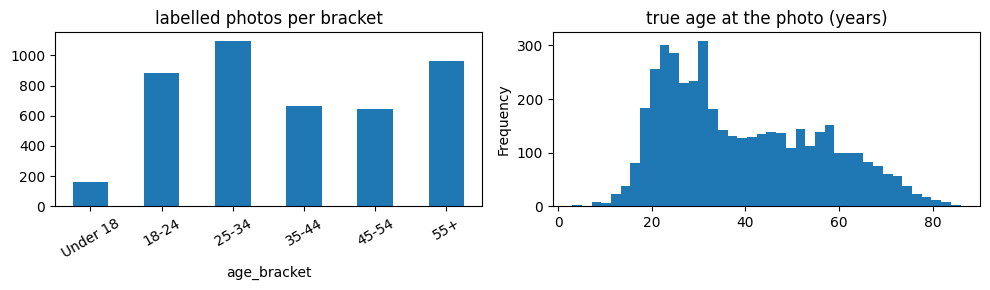

date precision: {'day': 4098, 'year': 230, 'month': 83}


In [23]:
if RERUN["labels"] or not Path("data/labelled.csv").exists():
    need_contact()
    label_photos()
else:
    print("data/labelled.csv exists -> stage 2 skipped (RERUN['labels'] = True to redo it)")
labelled = pd.read_csv("data/labelled.csv")
print(len(labelled), "photos with a labelled true age bracket")
if Path("data/step2_all.csv").exists():
    _all = pd.read_csv("data/step2_all.csv")
    print(f"\nStage-2 funnel ({len(_all)} candidates in):"); print(_all["drop_reason"].value_counts().to_string())
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
labelled["age_bracket"].value_counts().reindex(BRACKETS).plot.bar(ax=ax[0], title="labelled photos per bracket", rot=30)
labelled["age_int"].plot.hist(bins=40, ax=ax[1], title="true age at the photo (years)")
plt.tight_layout(); plt.show()
print("date precision:", labelled["date_precision"].value_counts().to_dict())

### Manual spot check of the labels (needed for the README)
Commons dates are not guaranteed to be capture dates (a scan or upload date can slip through). Open about 30 of the links below, look at the Commons description and the person's apparent age, and count how many dates look **wrong**. Put the number in `SPOT_CHECK_WRONG`. With 0 wrong out of 30, say in the README: "0/30 wrong, so the label error rate is probably under about 10% (95% upper bound)".

In [24]:
_spot = labelled.sample(min(30, len(labelled)), random_state=7)[["name", "birth_date", "raw_date", "photo_date", "age_int", "age_bracket", "file_page"]]
display(_spot.reset_index(drop=True))
SPOT_CHECK_WRONG = None      # <- after checking the links, e.g. SPOT_CHECK_WRONG = 2

,name,birth_date,raw_date,photo_date,age_int,age_bracket,file_page
0,Pete Visclosky,1949-08-13,2015-09-22,2015-09-22,66.0,55+,https://commons.wikimedia.org/wiki/File:Pete_Visclosky_official_ph...
1,Sarah Bock,2006-08-15,2025-03-22 15:44:01,2025-03-22,18.0,18-24,https://commons.wikimedia.org/wiki/File:Sarah_Bock_-_Severance.jpg
2,Vladimír Kadlec,1957-07-09,1984-07-28,1984-07-28,27.0,25-34,https://commons.wikimedia.org/wiki/File:Vladi_1984.jpg
3,Vangelis Alexandris,1951-02-02,2016-10-08 18:03:46,2016-10-08,65.0,55+,https://commons.wikimedia.org/wiki/File:VangelisAlexandris.jpg
4,Warren Hue,2002-06-20,2022-06-01,2022-06-01,19.0,18-24,https://commons.wikimedia.org/wiki/File:Warren_Hue_in_2022.png
5,Tony Wegas,1965-05-03,2015-05-18 20:36:34,2015-05-18,50.0,45-54,https://commons.wikimedia.org/wiki/File:Tony_Wegas_Euro_Fan_Cafe_2...
6,Suzanne Somers,1946-10-16,1977-06-28,1977-06-28,30.0,25-34,https://commons.wikimedia.org/wiki/File:Suzanne_Somers_1977.JPG
7,Herbert Gantschacher,1956-12-02,"Taken on 1 July 2010, 18:34:31",2010-07-01,53.0,45-54,https://commons.wikimedia.org/wiki/File:Gantschacher_Prora_2010_-_...
8,Bhaswar Chatterjee,1975-08-03,2020-04-15,2020-04-15,44.0,35-44,https://commons.wikimedia.org/wiki/File:Bhaswar_Chattopadhyay.jpg
9,Lluís-Anton Baulenas,1958-09-21,2018-02-01 20:47:11,2018-02-01,59.0,55+,https://commons.wikimedia.org/wiki/File:Lluis-Anton_Baulenas_(2018...


## 3. Photos, face filter and train / validation / test split
* **Balanced subset:** up to 260 photos per bracket (all "Under 18" photos), because the models need a few hundred training photos and a balanced test set, not all ~4,500.
* **Download:** the original file when it is small, otherwise a 960 px standard Wikimedia thumbnail (Wikimedia rate-limits non-standard thumbnail widths); everything is resized locally to <= 960 px wide. A time budget stops the stage cleanly (re-run to resume), and an early abort triggers when HTTP 429 answers outnumber successes.
* **Face rule** (identical in the live API): YuNet detector, score >= 0.8; **exactly one main face**, at least 2x as wide as any other face and at least 60 px wide. Group photos, no-face photos and tiny faces are dropped.
* **Split:** one photo per person, so splitting by photo is splitting by person; photos shared by several people (same Commons file) are de-duplicated. Test: up to 45 per bracket (balanced). Validation: up to 20 per bracket. Everything else: training.

In [25]:
# --- tunable settings of this stage (the face rule must stay identical to the live API)
IMG_DIR, FACE_DIR = "data/images", "data/faces"
MODEL_URL = ("https://github.com/opencv/opencv_zoo/raw/main/models/"
             "face_detection_yunet/face_detection_yunet_2023mar.onnx")
MODEL_PATH = "data/yunet.onnx"

PER_BRACKET = 260        # candidates per bracket to download (Under 18 uses all it has)
MAX_MINUTES = 25         # stop downloading after this long (rerun to continue)
WORKERS = 4
MAX_W = 960              # keep images at most this wide (a standard Wikimedia thumbnail width)
MAX_BYTES = 25_000_000   # skip files larger than this
MAX_ORIGINAL_PIXELS = 8_000_000

SCORE_MIN = 0.8          # face rule, identical to the live API (agepred/faces.py)
MIN_FACE_PX = 60
DOMINANCE = 2.0
MARGIN = 0.3

TEST_PER_BRACKET = 45
VAL_PER_BRACKET = 20

In [26]:
# ----------------------------------------------------------------- subset + URLs
def choose_subset(df, per_bracket=PER_BRACKET, seed=SEED):
    """Balanced by bracket; photos already on disk are always kept (they cost nothing)."""
    have = set()
    if os.path.isdir(IMG_DIR):
        have = {os.path.splitext(f)[0] for f in os.listdir(IMG_DIR)
                if os.path.getsize(os.path.join(IMG_DIR, f)) > 0}
    parts = []
    for b in BRACKETS:
        g = df[df["age_bracket"] == b]
        already = g[g["qid"].isin(have)]
        rest = g[~g["qid"].isin(have)].sample(frac=1, random_state=seed)
        parts += [already, rest.head(max(0, per_bracket - len(already)))]
    return pd.concat(parts)


def standard_thumb(thumb_url):
    """800px thumbnail URL from step 2 -> 960px (a standard Wikimedia width)."""
    head, tail = thumb_url.rsplit("/", 1)
    return head + "/" + re.sub(r"^\d+px-", "960px-", tail)


def candidate_urls(row):
    w, h = row.get("width"), row.get("height")
    orig = row.get("image_url") if isinstance(row.get("image_url"), str) else None
    thumb = row.get("thumb_url") if isinstance(row.get("thumb_url"), str) else None
    thumb = standard_thumb(thumb) if thumb and "/thumb/" in thumb else None
    if orig and (pd.isna(w) or w <= MAX_W):
        return [orig]
    if orig and pd.notna(w) and pd.notna(h) and w * h <= MAX_ORIGINAL_PIXELS:
        return [orig] + ([thumb] if thumb else [])
    return [thumb] if thumb else ([orig] if orig else [])

In [27]:
# ----------------------------------------------------------------- download
_stats = {"429": 0, "ok": 0, "aborted": False}
_stop = threading.Event()
_lock = threading.Lock()


def _retry_after(r, default):
    try:
        return min(float(r.headers.get("Retry-After", default)), 60.0)
    except ValueError:
        return default


def fetch_one(qid, urls, path, deadline):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return qid, "ok"
    last = "no_url"
    for url in urls:
        for attempt in range(3):
            if _stop.is_set():
                return qid, "skipped_throttled"
            if time.time() > deadline:
                return qid, "skipped_time_budget"
            try:
                r = requests.get(url, headers=UA, timeout=40, stream=True)
            except requests.RequestException:
                last = "network_error"
                time.sleep(2)
                continue
            if r.status_code == 200:
                data, too_big = bytearray(), False
                for chunk in r.iter_content(1 << 16):
                    data += chunk
                    if len(data) > MAX_BYTES:
                        too_big = True
                        break
                r.close()
                if too_big:
                    last = "too_big"
                    break
                img = cv2.imdecode(np.frombuffer(bytes(data), np.uint8), cv2.IMREAD_COLOR)
                if img is None:
                    last = "undecodable"
                    break
                h, w = img.shape[:2]
                if w > MAX_W:
                    img = cv2.resize(img, (MAX_W, int(round(h * MAX_W / w))), interpolation=cv2.INTER_AREA)
                cv2.imwrite(path, img, [cv2.IMWRITE_JPEG_QUALITY, 92])
                with _lock:
                    _stats["ok"] += 1
                return qid, "ok"
            if r.status_code == 429:
                with _lock:
                    _stats["429"] += 1  # every rate-limit answer is counted, not only final failures
                    if (_stats["429"] >= 30 and _stats["ok"] * 3 < _stats["429"]
                            and not _stats["aborted"]):
                        _stats["aborted"] = True   # rate-limit answers outnumber successes 3:1
                        _stop.set()
                        print("\n!! Wikimedia is throttling this connection (30+ HTTP 429 answers, almost no "
                              "successes). Stopping early instead of waiting for hours.", flush=True)
                last = "http_429"
                _stop.wait(_retry_after(r, 2 ** (attempt + 1)))   # 2s, 4s, 8s unless the server says; wakes up on abort
                continue
            last = f"http_{r.status_code}"
            break
    return qid, last


def download_all(todo, max_minutes=MAX_MINUTES):
    deadline = time.time() + max_minutes * 60
    _stop.clear()
    _stats.update({"429": 0, "ok": 0, "aborted": False})
    jobs = [(row["qid"], candidate_urls(row), f"{IMG_DIR}/{row['qid']}.jpg")
            for _, row in todo.iterrows()]
    status, t0 = {}, time.time()
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        futs = [ex.submit(fetch_one, q, u, p, deadline) for q, u, p in jobs]
        for i, f in enumerate(as_completed(futs), 1):
            q, st = f.result()
            status[q] = st
            if i % 50 == 0 or i == len(jobs):
                ok = sum(v == "ok" for v in status.values())
                el = time.time() - t0
                print(f"  {i}/{len(jobs)} done | ok {ok} | failed {i - ok} | 429 answers so far {_stats['429']} | "
                      f"{i / el:.1f} img/s | {el / 60:.1f} min", flush=True)
    return status

In [28]:
# ----------------------------------------------------------------- faces
def ensure_model():
    if not os.path.exists(MODEL_PATH):
        os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
        r = requests.get(MODEL_URL, timeout=60)
        r.raise_for_status()
        with open(MODEL_PATH, "wb") as f:
            f.write(r.content)
    if os.path.getsize(MODEL_PATH) < 100_000:
        raise RuntimeError("YuNet model file looks wrong (too small). Delete data/yunet.onnx and re-download.")


def pick_main_face(faces):
    real = [f for f in faces if f[14] >= SCORE_MIN]
    if not real:
        return None, "no_face"
    real.sort(key=lambda f: f[2] * f[3], reverse=True)
    main = real[0]
    if len(real) > 1 and main[2] < DOMINANCE * real[1][2]:
        return None, "multiple_faces"
    if main[2] < MIN_FACE_PX or main[3] < MIN_FACE_PX:
        return None, "face_too_small"
    return main, None


def crop_face(img, f):
    h, w = img.shape[:2]
    x, y, fw, fh = (float(v) for v in f[:4])    # plain floats: same arithmetic as the live API
    mx, my = fw * MARGIN, fh * MARGIN
    x0, y0 = int(max(0, x - mx)), int(max(0, y - my))
    x1, y1 = int(min(w, x + fw + mx)), int(min(h, y + fh + my))
    return img[y0:y1, x0:x1]

In [29]:
# --- the full stage: subset -> download -> face filter -> split -> save
def build_dataset(inp="data/labelled.csv", detector=None, max_minutes=MAX_MINUTES):
    os.makedirs(IMG_DIR, exist_ok=True)
    os.makedirs(FACE_DIR, exist_ok=True)

    df = pd.read_csv(inp)
    assert df["qid"].is_unique, "qid must be unique"
    df = df.set_index("qid", drop=False)
    df["date_has_time"] = df["raw_date"].astype(str).str.contains(r"\d{1,2}:\d{2}")
    df["drop_reason"] = None
    for c in ["n_faces", "face_x", "face_y", "face_w", "face_h", "face_score"]:
        df[c] = np.nan
    print(f"Rows in: {len(df)}")

    dup = df.duplicated(subset="lead_file", keep="first")
    df.loc[dup, "drop_reason"] = "duplicate_image"

    pool = df[df["drop_reason"].isna()]
    subset = choose_subset(pool)
    df.loc[df.index.difference(subset.index).intersection(pool.index), "drop_reason"] = "not_selected"
    print(f"Selected {len(subset)} photos (balanced by bracket):",
          subset["age_bracket"].value_counts().reindex(BRACKETS).to_dict())

    status = download_all(subset, max_minutes)
    print("Download status:", pd.Series(status).value_counts().to_dict())
    if _stats["aborted"]:
        print("Aborted before face detection; data/final.csv was not changed.")
        return

    if detector is None:
        ensure_model()
        detector = cv2.FaceDetectorYN.create(MODEL_PATH, "", (320, 320), SCORE_MIN, 0.3, 5000)
    for q, st in status.items():
        if st != "ok":
            df.loc[q, "drop_reason"] = st
            continue
        img = cv2.imread(f"{IMG_DIR}/{q}.jpg")
        if img is None:
            df.loc[q, "drop_reason"] = "unreadable_image"
            continue
        h, w = img.shape[:2]
        detector.setInputSize((w, h))
        _, faces = detector.detect(img)
        faces = [] if faces is None else list(faces)
        df.loc[q, "n_faces"] = len(faces)
        face, why = pick_main_face(faces)
        if why:
            df.loc[q, "drop_reason"] = why
            continue
        cv2.imwrite(f"{FACE_DIR}/{q}.jpg", crop_face(img, face))
        df.loc[q, ["face_x", "face_y", "face_w", "face_h", "face_score"]] = [
            face[0], face[1], face[2], face[3], face[14]]

    kept = df[df["drop_reason"].isna()].sample(frac=1, random_state=SEED).copy()
    kept["split"] = "train"
    for b in BRACKETS:
        idx = kept.index[kept["age_bracket"] == b]
        n_test = min(TEST_PER_BRACKET, int(0.4 * len(idx)))
        n_val = min(VAL_PER_BRACKET, int(0.15 * len(idx)))
        kept.loc[idx[:n_test], "split"] = "test"
        kept.loc[idx[n_test:n_test + n_val], "split"] = "val"

    df["split"] = kept["split"]
    df.loc[kept.index, "drop_reason"] = "KEPT"
    df.to_csv("data/step3_all.csv", index=False)
    df.loc[kept.index].to_csv("data/final.csv", index=False)

    print("\n=== Funnel (copy into README) ===")
    print(df["drop_reason"].value_counts().to_string())
    print(f"\nKept {len(kept)} of {len(df)}")
    print("\nSplit x bracket:")
    print(pd.crosstab(kept["age_bracket"], kept["split"]).reindex(BRACKETS).to_string())
    if (pd.Series(status) == "skipped_time_budget").any():
        print("\nTime budget reached: run this cell again to continue downloading.")

In [30]:
# Self-check of the face rule, URL choice and subset balance (no network, no model file)
_f = lambda x, w, sc=0.95: np.array([x, 100, w, w] + [0] * 10 + [sc], dtype=np.float32)
assert pick_main_face([])[1] == "no_face"
assert pick_main_face([_f(0, 200, 0.5)])[1] == "no_face"                       # low-confidence detection
assert pick_main_face([_f(0, 200), _f(400, 190)])[1] == "multiple_faces"        # two similar faces: refuse to guess
assert pick_main_face([_f(0, 40)])[1] == "face_too_small"
assert pick_main_face([_f(0, 200), _f(500, 60)])[1] is None                     # 200 >= 2 x 60: dominant face accepted
_c = crop_face(np.zeros((800, 800, 3), np.uint8), _f(100, 200))
assert abs(_c.shape[0] - 320) <= 1 and abs(_c.shape[1] - 320) <= 1       # 200 px face + 30% margin on each side

_base = dict(image_url="https://upload.wikimedia.org/wikipedia/commons/a/ab/X.jpg",
             thumb_url="https://upload.wikimedia.org/wikipedia/commons/thumb/a/ab/X.jpg/800px-X.jpg")
assert candidate_urls({**_base, "width": 700, "height": 500}) == [_base["image_url"]]
_u = candidate_urls({**_base, "width": 2000, "height": 1500})
assert _u[0] == _base["image_url"] and _u[1].endswith("/960px-X.jpg")           # 800 px thumbnail rewritten to a standard size
assert candidate_urls({**_base, "width": 6000, "height": 4000}) == [standard_thumb(_base["thumb_url"])]

_t = pd.DataFrame({"qid": [f"S{i}" for i in range(600)], "age_bracket": np.repeat(BRACKETS, 100)})
_s = choose_subset(_t)
assert _s["qid"].is_unique and (_s["age_bracket"].value_counts() == min(100, PER_BRACKET)).all()
print("stage 3 self-checks passed: face rule, URL choice, balanced subset")

stage 3 self-checks passed: face rule, URL choice, balanced subset


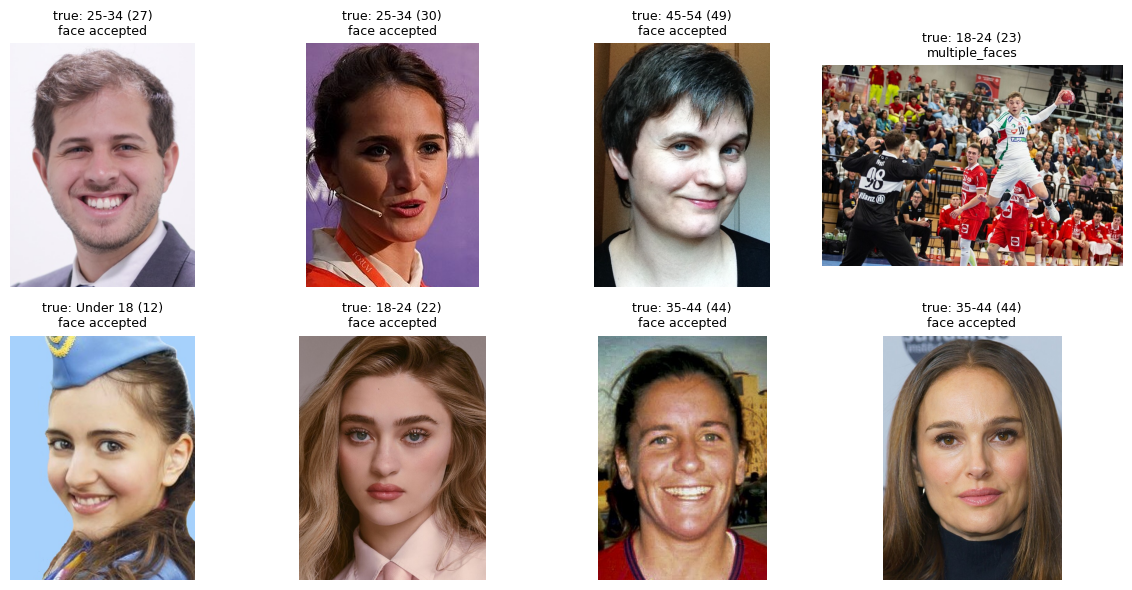

In [31]:
# Optional live check: download 8 random labelled photos with the REAL downloader and face detector, and look at the result
if LIVE_CHECKS:
    need_contact()
    ensure_model()
    _det = cv2.FaceDetectorYN.create(MODEL_PATH, "", (320, 320), SCORE_MIN, 0.3, 5000)
    Path("data/_live_check").mkdir(exist_ok=True)
    _sample = pd.read_csv("data/labelled.csv").sample(8, random_state=3)
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, (_, r) in zip(axes.ravel(), _sample.iterrows()):
        path = f"data/_live_check/{r['qid']}.jpg"
        _, st = fetch_one(r["qid"], candidate_urls(r), path, time.time() + 90)
        ax.axis("off")
        if st != "ok":
            ax.set_title(f"download: {st}", fontsize=8)
            continue
        img = cv2.imread(path); h, w = img.shape[:2]
        _det.setInputSize((w, h)); _, faces = _det.detect(img)
        face, why = pick_main_face([] if faces is None else list(faces))
        ax.imshow((crop_face(img, face) if face is not None else img)[:, :, ::-1])
        ax.set_title(f"true: {r['age_bracket']} ({int(r['age_int'])})\n{why or 'face accepted'}", fontsize=9)
    plt.tight_layout(); plt.show()
    shutil.rmtree("data/_live_check", ignore_errors=True)
else:
    print("LIVE_CHECKS = False -> skipped")

Rows in: 4411
Selected 1459 photos (balanced by bracket): {'Under 18': 159, '18-24': 260, '25-34': 260, '35-44': 260, '45-54': 260, '55+': 260}
  50/1459 done | ok 50 | failed 0 | 429 answers so far 12 | 1.2 img/s | 0.7 min
  100/1459 done | ok 100 | failed 0 | 429 answers so far 24 | 1.2 img/s | 1.4 min
  150/1459 done | ok 150 | failed 0 | 429 answers so far 36 | 1.2 img/s | 2.0 min
  200/1459 done | ok 200 | failed 0 | 429 answers so far 48 | 1.2 img/s | 2.7 min
  250/1459 done | ok 250 | failed 0 | 429 answers so far 64 | 1.2 img/s | 3.6 min
  300/1459 done | ok 300 | failed 0 | 429 answers so far 78 | 1.2 img/s | 4.3 min
  350/1459 done | ok 350 | failed 0 | 429 answers so far 92 | 1.1 img/s | 5.2 min
  400/1459 done | ok 400 | failed 0 | 429 answers so far 105 | 1.1 img/s | 5.9 min
  450/1459 done | ok 450 | failed 0 | 429 answers so far 120 | 1.1 img/s | 6.8 min
  500/1459 done | ok 500 | failed 0 | 429 answers so far 137 | 1.1 img/s | 7.6 min
  550/1459 done | ok 550 | failed 0

split,test,train,val
age_bracket,,,
Under 18,45,66,19
18-24,45,152,20
25-34,45,154,20
35-44,45,177,20
45-54,45,161,20
55+,45,167,20


Stage-3 funnel:
drop_reason
not_selected       2950
KEPT               1266
multiple_faces       95
no_face              59
face_too_small       39
duplicate_image       2


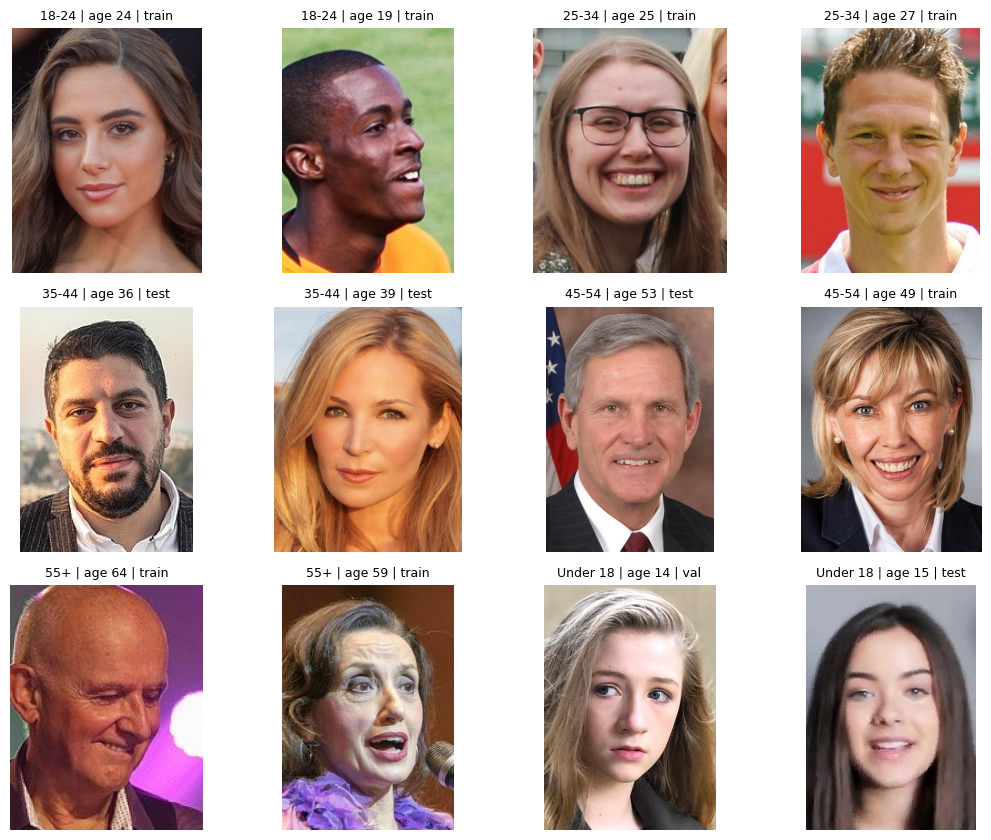

In [32]:
if RERUN["photos"] or not Path("data/final.csv").exists():
    need_contact()
    build_dataset()
else:
    print("data/final.csv exists -> stage 3 skipped (RERUN['photos'] = True to redo it)")
final = pd.read_csv("data/final.csv")
assert final["qid"].is_unique, "data/final.csv has duplicate photo ids: one person must appear only once"
print(len(final), "usable photos")
display(pd.crosstab(final["age_bracket"], final["split"]).reindex(BRACKETS))
if Path("data/step3_all.csv").exists():
    print("Stage-3 funnel:"); print(pd.read_csv("data/step3_all.csv")["drop_reason"].value_counts().to_string())
_missing = [q for q in final["qid"] if not Path(f"data/faces/{q}.jpg").exists()]
assert not _missing, f"{len(_missing)} face crops are missing in data/faces (copy the folder from Colab)"
_g = pd.concat([g.sample(min(len(g), 2), random_state=SEED) for _, g in final.groupby("age_bracket")])
fig, axes = plt.subplots(3, 4, figsize=(11, 8.5))
for ax, (_, r) in zip(axes.ravel(), _g.iterrows()):
    ax.imshow(cv2.imread(f"data/faces/{r['qid']}.jpg")[:, :, ::-1]); ax.axis("off")
    ax.set_title(f"{r['age_bracket']} | age {int(r['age_int'])} | {r['split']}", fontsize=9)
plt.tight_layout(); plt.show()

## 4. CV approach: pretrained ViT age model (+ a linear probe trained on our data)
**Pretrained model:** [`nateraw/vit-age-classifier`](https://huggingface.co/nateraw/vit-age-classifier), a ViT-base fine-tuned by its author on the FairFace dataset (9 age bins). It is a pretrained model, which the assignment allows; we never train or test on FairFace. Name it in the README.

Two variants, scored on the same faces:
1. **cv_zeroshot** - the model as it is. Its 9 bins are mapped to our 6 brackets by interval overlap (e.g. the "10-19" bin sends 80% of its probability to *Under 18* and 20% to *18-24*). Confidence = the winning bracket's probability. Exact age = probability-weighted bin midpoint.
2. **cv_probe** - a *linear probe*: logistic regression (bracket) and ridge regression (exact age) trained on **our train split** on top of the frozen ViT embedding. This is not full fine-tuning. The regularisation strengths are chosen on the validation split; the test split is not touched.

CPU note: embeddings are computed once and cached in `data/cv_features.npz` (keyed by photo id, so a cache copied from Colab is reused). `MAX_TRAIN_PER_BRACKET` limits how many training faces are embedded.

In [33]:
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.preprocessing import StandardScaler

MODEL_ID = "nateraw/vit-age-classifier"
FEATURE_CACHE = "data/cv_features.npz"
MAX_TRAIN_PER_BRACKET = 250        # CPU time saver
VIT_LABELS = ['0-2', '3-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', 'more than 70']

def bin_edges(label):
    """'20-29' -> [20, 30);  'more than 70' -> [70, 80)."""
    if label.lower().startswith("more"):
        return 70.0, 80.0
    a, b = label.split("-")
    return float(a), float(b) + 1.0


def bracket_matrix(bins):
    """M[i, j] = share of model bin i that lies inside our bracket j (rows sum to 1)."""
    M = np.zeros((len(bins), len(BRACKETS)))
    for i, (blo, bhi) in enumerate(bins):
        for j, (lo, hi) in enumerate(BRACKET_EDGES):
            M[i, j] = max(0.0, min(bhi, hi) - max(blo, lo)) / (bhi - blo)
    return M


def softmax(x):
    e = np.exp(x - x.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def load_vit():
    import torch
    from transformers import AutoImageProcessor, ViTForImageClassification
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    proc = AutoImageProcessor.from_pretrained(MODEL_ID)
    model = ViTForImageClassification.from_pretrained(MODEL_ID).eval()      # CPU
    labels = [model.config.id2label[i] for i in range(len(model.config.id2label))]
    assert labels == VIT_LABELS, f"unexpected model bins: {labels}"
    return proc, model


def extract_features(qids, proc, model, batch_size=16):
    """ViT [CLS] embedding (768-d) and the model's own 9-bin probabilities for each face crop."""
    import torch
    embs, probs = [], []
    with torch.no_grad():
        for i in tqdm(range(0, len(qids), batch_size), desc="ViT features (CPU)"):
            imgs = [Image.open(f"data/faces/{q}.jpg").convert("RGB") for q in qids[i:i + batch_size]]
            inp = proc(images=imgs, return_tensors="pt")
            h = model.vit(pixel_values=inp["pixel_values"]).last_hidden_state[:, 0]
            embs.append(h.float().numpy())
            probs.append(model.classifier(h).float().softmax(-1).numpy())
    return np.concatenate(embs), np.concatenate(probs)


def get_features(qids):
    """Cached by photo id; only faces that are not in the cache are computed."""
    cache = {}
    if Path(FEATURE_CACHE).exists():
        z = np.load(FEATURE_CACHE, allow_pickle=True)
        cache = {str(q): (e, p) for q, e, p in zip(z["qids"], z["emb"], z["probs"])}
    missing = [q for q in qids if q not in cache]
    print(f"{len(qids) - len(missing)} faces found in the cache, {len(missing)} to compute")
    if missing:
        proc, model = load_vit()
        e, p = extract_features(missing, proc, model)
        cache.update({q: (e[i], p[i]) for i, q in enumerate(missing)})
        keys = list(cache)
        np.savez(FEATURE_CACHE, qids=np.array(keys), emb=np.stack([cache[k][0] for k in keys]),
                 probs=np.stack([cache[k][1] for k in keys]))
    return np.stack([cache[q][0] for q in qids]), np.stack([cache[q][1] for q in qids])


def mae_on_day_precision(d, pred_col="pred_age"):
    m = d["age_exact"].notna()
    return float((d.loc[m, pred_col] - d.loc[m, "age_exact"]).abs().mean())


def cv_predictions(df, emb, probs):
    """df rows are aligned with emb/probs. Returns (zero-shot preds, probe preds, probe weights)."""
    bins = [bin_edges(l) for l in VIT_LABELS]
    mids = np.array([(a + b) / 2 for a, b in bins])
    M = bracket_matrix(bins)
    tr, va = (df["split"] == "train").values, (df["split"] == "val").values
    ev = (df["split"] != "train").values

    # 1) zero-shot
    bp = probs @ M
    zs_bracket = np.array(BRACKETS)[bp.argmax(1)]
    zs = pd.DataFrame({"qid": df["qid"], "split": df["split"], "pred_bracket": zs_bracket,
                       "pred_age": [clamp_age(a, b) for a, b in zip(probs @ mids, zs_bracket)],
                       "confidence": bp.max(1).round(4)})

    # 2) linear probe on the frozen embedding
    scaler = StandardScaler().fit(emb[tr])
    X = scaler.transform(emb)
    y = df["age_bracket"].values
    best = (-1, None, None)
    for C in [0.0005, 0.002, 0.01, 0.05, 0.2]:
        clf = LogisticRegression(C=C, max_iter=3000, class_weight="balanced").fit(X[tr], y[tr])
        acc = (clf.predict(X[va]) == y[va]).mean()
        print(f"  logistic C={C:<7} validation accuracy = {acc:.3f}")
        if acc > best[0]:
            best = (acc, C, clf)
    _, bestC, clf = best
    day = df["age_exact"].notna().values
    best_r = (1e9, None, None)
    for alpha in [10, 100, 1000, 3000, 10000]:
        reg = Ridge(alpha=alpha).fit(X[tr & day], df.loc[tr & day, "age_exact"].values)
        mae = np.abs(reg.predict(X[va & day]) - df.loc[va & day, "age_exact"].values).mean()
        print(f"  ridge alpha={alpha:<6} validation MAE = {mae:.2f} years")
        if mae < best_r[0]:
            best_r = (mae, alpha, reg)
    _, bestA, reg = best_r
    print(f"Chosen: C={bestC}, alpha={bestA}")

    p = clf.predict_proba(X)
    pr_bracket = clf.classes_[p.argmax(1)]
    pr = pd.DataFrame({"qid": df["qid"], "split": df["split"], "pred_bracket": pr_bracket,
                       "pred_age": [clamp_age(a, b) for a, b in zip(reg.predict(X), pr_bracket)],
                       "confidence": p.max(1).round(4)})
    weights = dict(mean=scaler.mean_, scale=scaler.scale_, clf_w=clf.coef_, clf_b=clf.intercept_,
                   classes=np.array(clf.classes_), reg_w=reg.coef_, reg_b=np.array(reg.intercept_),
                   model_id=np.array(MODEL_ID))
    return zs[ev], pr[ev], weights

In [34]:
final = pd.read_csv("data/final.csv")
train = final[final["split"] == "train"]
train = pd.concat([g.sample(min(len(g), MAX_TRAIN_PER_BRACKET), random_state=SEED) for _, g in train.groupby("age_bracket")])
cv_df = pd.concat([train, final[final["split"] != "train"]]).reset_index(drop=True)
print("faces used:", cv_df["split"].value_counts().to_dict())

if RERUN["cv"] or not (Path("results/preds_cv_probe.csv").exists() and Path("models/cv_probe.npz").exists()):
    emb, probs = get_features(cv_df["qid"].tolist())
    zs_preds, probe_preds, weights = cv_predictions(cv_df, emb, probs)
    zs_preds.to_csv("results/preds_cv_zeroshot.csv", index=False)
    probe_preds.to_csv("results/preds_cv_probe.csv", index=False)
    np.savez("models/cv_probe.npz", **weights)       # plain numpy: the API needs no scikit-learn
    print("saved results/preds_cv_*.csv and models/cv_probe.npz")
else:
    print("CV predictions already exist -> stage 4 skipped (RERUN['cv'] = True to redo)")

# quick look (the real evaluation is stage 6; do not tune anything on the test split)
for name in ["cv_zeroshot", "cv_probe"]:
    p = pd.read_csv(f"results/preds_{name}.csv").merge(final[["qid", "age_bracket", "age_exact"]], on="qid")
    for split in ["val", "test"]:
        d = p[p["split"] == split]
        print(f"{name:12s} {split:5s} n={len(d):4d}  bracket accuracy={(d.pred_bracket == d.age_bracket).mean():.3f}  MAE={mae_on_day_precision(d):.2f}")

faces used: {'train': 877, 'test': 270, 'val': 119}
0 faces found in the cache, 1266 to compute


preprocessor_config.json:   0%|          | 0.00/197 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/850 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViT features (CPU):   0%|          | 0/80 [00:00<?, ?it/s]

  logistic C=0.0005  validation accuracy = 0.479
  logistic C=0.002   validation accuracy = 0.487
  logistic C=0.01    validation accuracy = 0.521
  logistic C=0.05    validation accuracy = 0.487
  logistic C=0.2     validation accuracy = 0.471
  ridge alpha=10     validation MAE = 9.64 years
  ridge alpha=100    validation MAE = 7.12 years
  ridge alpha=1000   validation MAE = 6.58 years
  ridge alpha=3000   validation MAE = 6.61 years
  ridge alpha=10000  validation MAE = 6.83 years
Chosen: C=0.01, alpha=1000
saved results/preds_cv_*.csv and models/cv_probe.npz
cv_zeroshot  val   n= 119  bracket accuracy=0.471  MAE=6.87
cv_zeroshot  test  n= 270  bracket accuracy=0.426  MAE=7.43
cv_probe     val   n= 119  bracket accuracy=0.521  MAE=6.65
cv_probe     test  n= 270  bracket accuracy=0.541  MAE=6.22


## 5. LLM approach (same photos, same test split)
The LLM sees **only the face crop**: no name, no birth date, no photo date, no page text. That keeps the comparison with the CV model fair and stops it from "remembering" a famous person's birth year. It is asked for strict JSON: `{"age", "bracket", "confidence"}`. The stated bracket is used for the bracket metric; the age is clamped into that bracket (the same rule the CV models use), and parse failures are counted and reported, not hidden.

**Backends** (`LLM_BACKEND` in the configuration cell):
* `gemini` - Google AI Studio free tier. Google no longer publishes free-tier quotas and model names change, so run the smoke test below first. If the daily quota runs out the run stops and **resumes** when you run the cell again.
* `qwen_local` - a small open model on your CPU. It needs no key or quota but is slow (tens of seconds per photo); use a small `LLM_TEST_LIMIT`.

Test photos are chosen **stratified by bracket** with a fixed seed, so every approach is later compared on identical photos.

In [35]:
PROMPT = (
    "You are an expert at estimating a person's age from a photograph of their face. "
    "Estimate how old the person was when this photo was taken. "
    "Use only what is visible in the image. "
    'Reply with ONLY a JSON object and no other text: '
    '{"age": <integer number of years>, '
    '"bracket": "<exactly one of: Under 18, 18-24, 25-34, 35-44, 45-54, 55+>", '
    '"confidence": <number between 0 and 1>}. '
    "The bracket must contain the age."
)

def parse_answer(raw):
    """Return dict(pred_bracket, pred_age, confidence, raw_bracket, parse_ok, note)."""
    out = {"pred_bracket": None, "pred_age": None, "confidence": None,
           "raw_bracket": None, "parse_ok": False, "note": ""}
    if not raw:
        out["note"] = "empty"
        return out
    m = re.search(r"\{.*?\}", raw, re.S)
    if not m:
        out["note"] = "no_json"
        return out
    try:
        obj = json.loads(m.group(0))
        age = float(obj["age"])
    except Exception:
        out["note"] = "bad_json"
        return out
    if not (0 <= age <= 110):
        out["note"] = "age_out_of_range"
        return out
    raw_b = str(obj.get("bracket", "")).replace("\u2013", "-").replace("\u2014", "-").strip()
    out["raw_bracket"] = raw_b
    # primary bracket = the one the model stated; fall back to the one implied by the age
    bracket = raw_b if raw_b in BRACKETS else bracket_of_age(age)
    try:
        conf = min(max(float(obj.get("confidence", 0.5)), 0.0), 1.0)
    except Exception:
        conf = 0.5
    out.update(pred_bracket=bracket, pred_age=clamp_age(age, bracket),
               confidence=round(conf, 3), parse_ok=True)
    if raw_b and raw_b != bracket_of_age(age):
        out["note"] = "bracket_age_mismatch"
    return out

class QuotaExhausted(RuntimeError):
    pass


def call_with_retries(call, jpeg, retries=5):
    last = None
    for attempt in range(retries):
        try:
            return call(jpeg)
        except Exception as e:  # noqa: BLE001  (SDK exceptions differ between backends)
            msg = str(e)
            last = msg
            if "PerDay" in msg or "per day" in msg.lower():
                raise QuotaExhausted(msg[:300])
            if "429" in msg or "RESOURCE_EXHAUSTED" in msg or "503" in msg or "UNAVAILABLE" in msg:
                wait = 20 * (attempt + 1)
                print(f"  rate limited / overloaded, waiting {wait}s")
                time.sleep(wait)
                continue
            if attempt < retries - 1:
                time.sleep(3)
                continue
    return json.dumps({"error": (last or "unknown")[:200]})


def _gemini_client():
    from google import genai
    key = os.environ.get("GEMINI_API_KEY")
    if not key:
        key = getpass.getpass("Gemini API key (hidden input, not saved anywhere): ")
        os.environ["GEMINI_API_KEY"] = key
    return genai.Client(api_key=key)


def list_gemini_models():
    for m in _gemini_client().models.list():
        if "generateContent" in (getattr(m, "supported_actions", None) or []):
            print(m.name)


def make_gemini(model_name=None):
    from google.genai import types
    model_name = model_name or GEMINI_MODEL
    client = _gemini_client()

    def call(jpeg_bytes):
        resp = client.models.generate_content(
            model=model_name,
            contents=[types.Part.from_bytes(data=jpeg_bytes, mime_type="image/jpeg"), PROMPT],
            config=types.GenerateContentConfig(temperature=0.0, response_mime_type="application/json"))
        return resp.text

    return call


def make_qwen_local(model_id=None):
    import torch
    from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
    model_id = model_id or QWEN_ID
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(model_id, torch_dtype=torch.bfloat16).eval()
    processor = AutoProcessor.from_pretrained(model_id, min_pixels=128 * 28 * 28, max_pixels=256 * 28 * 28)

    def call(jpeg_bytes):
        img = Image.open(io.BytesIO(jpeg_bytes)).convert("RGB")
        messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": PROMPT}]}]
        text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = processor(text=[text], images=[img], return_tensors="pt")
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=60, do_sample=False)
        return processor.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)[0]

    return call


def select_llm_photos(split="test", limit=None):
    d = pd.read_csv("data/final.csv")
    d = d[d["split"] == split]
    if limit and limit < len(d):
        per = math.ceil(limit / len(BRACKETS))
        d = pd.concat([g.sample(min(len(g), per), random_state=SEED) for _, g in d.groupby("age_bracket")])
    return d


def build_llm_preds(backend):
    meta = pd.read_csv("data/final.csv")[["qid", "split"]]
    rows = []
    for split in ("val", "test"):
        path = f"results/llm_{backend}_{split}.jsonl"
        if Path(path).exists():
            for line in open(path):
                if line.strip():
                    r = json.loads(line)
                    rows.append({"qid": r["qid"], "raw": r["raw"], **parse_answer(r["raw"])})
    if not rows:
        return None
    out = pd.DataFrame(rows).merge(meta, on="qid", how="left")
    out.to_csv(f"results/preds_llm_{backend}.csv", index=False)
    ok = int(out["parse_ok"].sum())
    print(f"results/preds_llm_{backend}.csv: {len(out)} answers, {ok} parsed ({ok / len(out):.1%}), "
          f"{int((out['note'] == 'bracket_age_mismatch').sum())} with bracket/age mismatch")
    if ok < len(out):
        print(out.loc[~out["parse_ok"], "note"].value_counts().to_string())
    return out


def run_llm(split, backend, limit=None, call=None, sleep=None):
    """Resumable: every answer is appended to results/llm_<backend>_<split>.jsonl."""
    d = select_llm_photos(split, limit)
    cache = Path(f"results/llm_{backend}_{split}.jsonl")
    done = {json.loads(l)["qid"] for l in open(cache) if l.strip()} if cache.exists() else set()
    todo = d[~d["qid"].isin(done)]
    print(f"{backend}/{split}: {len(d)} photos selected, {len(done)} already answered, {len(todo)} to do")
    if len(todo):
        call = call or (make_gemini() if backend == "gemini" else make_qwen_local())
        sleep = (GEMINI_SLEEP if backend == "gemini" else 0.0) if sleep is None else sleep
        with open(cache, "a") as f:
            for q in tqdm(todo["qid"], desc=f"{backend} {split}"):
                jpeg = open(f"data/faces/{q}.jpg", "rb").read()
                try:
                    raw = call_with_retries(call, jpeg)
                except QuotaExhausted as e:
                    print("\nDaily quota exhausted - run this cell again later; it resumes.\n", str(e)[:200])
                    break
                f.write(json.dumps({"qid": q, "raw": raw}) + "\n")
                f.flush()
                if sleep:
                    time.sleep(sleep)
    return build_llm_preds(backend)

In [36]:
# Smoke test on 3 validation photos: prints the raw answer and how it was parsed. Check this BEFORE the long run.
# (For the Gemini backend, list_gemini_models() shows which model names your key can use.)
if LLM_BACKEND != "none":
    _call = make_gemini() if LLM_BACKEND == "gemini" else make_qwen_local()
    for q in select_llm_photos("val", 3)["qid"]:
        raw = call_with_retries(_call, open(f"data/faces/{q}.jpg", "rb").read())
        print(q, "->", raw[:150].replace("\n", " "), "\n   parsed:", parse_answer(raw))
else:
    print("LLM_BACKEND = 'none': the LLM approach is skipped")

Gemini API key (hidden input, not saved anywhere): ··········
Q122732719 -> {"age": 21, "bracket": "18-24", "confidence": 0.9} 
   parsed: {'pred_bracket': '18-24', 'pred_age': 21, 'confidence': 0.9, 'raw_bracket': '18-24', 'parse_ok': True, 'note': ''}
Q168486 -> {"age": 32, "bracket": "25-34", "confidence": 0.85} 
   parsed: {'pred_bracket': '25-34', 'pred_age': 32, 'confidence': 0.85, 'raw_bracket': '25-34', 'parse_ok': True, 'note': ''}
Q289398 -> {"age": 48, "bracket": "45-54", "confidence": 0.85} 
   parsed: {'pred_bracket': '45-54', 'pred_age': 48, 'confidence': 0.85, 'raw_bracket': '45-54', 'parse_ok': True, 'note': ''}
Q44707 -> {"age": 56, "bracket": "55+", "confidence": 0.9} 
   parsed: {'pred_bracket': '55+', 'pred_age': 56, 'confidence': 0.9, 'raw_bracket': '55+', 'parse_ok': True, 'note': ''}
Q458300 -> {"age": 48, "bracket": "45-54", "confidence": 0.85} 
   parsed: {'pred_bracket': '45-54', 'pred_age': 48, 'confidence': 0.85, 'raw_bracket': '45-54', 'parse_ok': True, 'no

In [37]:
if LLM_BACKEND != "none":
    llm_preds = run_llm("test", LLM_BACKEND, limit=LLM_TEST_LIMIT, call=globals().get("_call"))

gemini/test: 120 photos selected, 0 already answered, 120 to do


gemini test:   0%|          | 0/120 [00:00<?, ?it/s]

results/preds_llm_gemini.csv: 120 answers, 120 parsed (100.0%), 0 with bracket/age mismatch


## 6. Evaluation
All approaches are scored on the **same test photos**.
* **Headline table:** only photos that *every* approach answered (the LLM may have answered a subset because of quota/time).
* **Second table:** the CV approaches on the *full* test split.
* Metrics: bracket accuracy (95% bootstrap CI), within-one-bracket accuracy, macro-F1, confusion matrices, **MAE in years** (only photos with a day-precision date, so the true age is exact), calibration (ECE; is "confidence 0.8" right about 80% of the time?), accuracy by date type (camera timestamp vs uploader-typed date), per-bracket recall/MAE and an exact paired test between approaches (photos where only one approach is right).
* Error analysis: `results/worst_errors_<approach>.csv` lists the largest errors with their Commons links.

In [38]:
from scipy.stats import binomtest
from sklearn.metrics import confusion_matrix, f1_score

IDX = {b: i for i, b in enumerate(BRACKETS)}
RNG = np.random.RandomState(0)
N_BOOT = 2000

def boot_ci(values, stat=np.mean):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return (np.nan, np.nan)
    stats = [stat(values[RNG.randint(0, len(values), len(values))]) for _ in range(N_BOOT)]
    return (float(np.percentile(stats, 2.5)), float(np.percentile(stats, 97.5)))


def ece(conf, correct, bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    edges = np.linspace(0, 1, bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0 else (conf >= lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(total)


def evaluate(d):
    """d: rows with age_bracket (true), pred_bracket, age_exact, pred_age, confidence."""
    true = d["age_bracket"].map(IDX).values
    pred = d["pred_bracket"].map(IDX).values
    correct = (true == pred)
    res = {"n": int(len(d)),
           "accuracy": float(correct.mean()),
           "accuracy_ci95": boot_ci(correct),
           "within_one_bracket": float((np.abs(true - pred) <= 1).mean()),
           "macro_f1": float(f1_score(true, pred, labels=range(6), average="macro", zero_division=0))}
    day = d["age_exact"].notna().values
    err = np.abs(d.loc[day, "pred_age"].values - d.loc[day, "age_exact"].values)
    res.update(mae=float(err.mean()) if len(err) else float("nan"),
               mae_ci95=boot_ci(err), mae_n=int(day.sum()))
    conf = d["confidence"].astype(float).values
    res["mean_confidence"] = float(conf.mean())
    res["ece"] = ece(conf, correct)
    med = np.median(conf)
    hi = conf >= med
    res["acc_high_conf_half"] = float(correct[hi].mean()) if hi.any() else float("nan")
    res["acc_low_conf_half"] = float(correct[~hi].mean()) if (~hi).any() else float("nan")
    res["confusion"] = confusion_matrix(true, pred, labels=range(6)).tolist()
    res["per_bracket_recall"] = {b: float(correct[true == i].mean()) if (true == i).any() else None
                                 for b, i in IDX.items()}
    res["mae_by_true_bracket"] = {b: (float(np.abs(d.loc[day & (true == i), "pred_age"].values
                                                  - d.loc[day & (true == i), "age_exact"].values).mean())
                                      if (day & (true == i)).any() else None)
                                  for b, i in IDX.items()}
    if "date_has_time" in d.columns:
        for flag, name in [(True, "acc_camera_timestamp"), (False, "acc_date_only")]:
            m = (d["date_has_time"] == flag).values
            res[name] = float(correct[m].mean()) if m.any() else None
            res[name + "_n"] = int(m.sum())
    return res


def plot_confusion(cm, title, path):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    cm = np.array(cm)
    share = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(5.6, 4.8))
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(6)); ax.set_yticks(range(6))
    ax.set_xticklabels(BRACKETS, rotation=45, ha="right"); ax.set_yticklabels(BRACKETS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                    color="white" if share[i, j] > 0.5 else "black", fontsize=8)
    fig.tight_layout(); fig.savefig(path, dpi=160); plt.close(fig)


def fmt_ci(x, pct=False):
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return "n/a"
    return f"{x * 100:.1f}%" if pct else f"{x:.2f}"


def load_preds(test):
    preds, notes = {}, []
    for f in sorted(glob.glob("results/preds_*.csv")):
        name = os.path.basename(f)[len("preds_"):-len(".csv")]
        p = pd.read_csv(f)
        if "parse_ok" in p.columns:
            failed = int((~p.loc[p["split"] == "test", "parse_ok"].astype(bool)).sum())
            p = p[p["parse_ok"].astype(bool)]
            if failed:
                notes.append(f"{name}: {failed} test answers could not be parsed and are excluded")
        p = p[p["qid"].isin(test["qid"])][["qid", "pred_bracket", "pred_age", "confidence"]].dropna(subset=["pred_bracket", "pred_age"])
        preds[name] = p.set_index("qid")
        print(f"{name}: {len(p)} of {len(test)} test photos answered")
    return preds, notes


def score_scope(test, preds, names, prefix, extras):
    common = set(test["qid"])
    for n in names:
        common &= set(preds[n].index)
    base = test[test["qid"].isin(common)].set_index("qid")
    frames = {n: base.join(preds[n][["pred_bracket", "pred_age", "confidence"]]) for n in names}
    results = {n: evaluate(frames[n]) for n in names}
    for n in names:
        plot_confusion(results[n]["confusion"], f"{n} (n={len(base)})", f"results/confusion_{prefix}{n}.png")
        if extras:
            d2 = frames[n][frames[n]["age_exact"].notna()].copy()
            d2["abs_error"] = (d2["pred_age"] - d2["age_exact"]).abs()
            cols = [c for c in ["name", "birth_date", "photo_date", "age_exact", "pred_age", "age_bracket",
                                "pred_bracket", "confidence", "abs_error", "file_page"] if c in d2.columns]
            d2.sort_values("abs_error", ascending=False).head(25)[cols].to_csv(f"results/worst_errors_{n}.csv")
    pairs = []
    if extras:
        for i in range(len(names)):
            for j in range(i + 1, len(names)):
                a, b = frames[names[i]], frames[names[j]]
                ca, cb = (a["pred_bracket"] == a["age_bracket"]).values, (b["pred_bracket"] == b["age_bracket"]).values
                oa, ob = int((ca & ~cb).sum()), int((~ca & cb).sum())
                pairs.append({"a": names[i], "b": names[j], "only_a_correct": oa, "only_b_correct": ob,
                              "p_value": float(binomtest(oa, oa + ob, 0.5).pvalue) if oa + ob else 1.0})
    return len(base), results, pairs


def tables_md(n, results, pairs, title):
    L = [f"### {title}", "", f"Test photos used: **{n}**", "",
         "| Approach | Bracket accuracy (95% CI) | Within 1 bracket | Macro-F1 | MAE years (95% CI) | MAE n |", "|---|---|---|---|---|---|"]
    for k, r in results.items():
        L.append(f"| {k} | {r['accuracy'] * 100:.1f}% ({fmt_ci(r['accuracy_ci95'][0], True)}-{fmt_ci(r['accuracy_ci95'][1], True)}) | "
                 f"{r['within_one_bracket'] * 100:.1f}% | {r['macro_f1']:.3f} | {r['mae']:.2f} ({r['mae_ci95'][0]:.2f}-{r['mae_ci95'][1]:.2f}) | {r['mae_n']} |")
    L += ["", "**Confidence quality** (is a confidence of 0.8 right about 80% of the time?)", "",
          "| Approach | Mean confidence | Accuracy | ECE (lower is better) | Acc. top-half confidence | Acc. bottom-half |", "|---|---|---|---|---|---|"]
    for k, r in results.items():
        L.append(f"| {k} | {r['mean_confidence']:.2f} | {r['accuracy']:.2f} | {r['ece']:.3f} | "
                 f"{fmt_ci(r['acc_high_conf_half'], True)} | {fmt_ci(r['acc_low_conf_half'], True)} |")
    L += ["", "**Per-bracket recall**", "", "| Approach | " + " | ".join(BRACKETS) + " |", "|---|" + "---|" * 6]
    for k, r in results.items():
        L.append(f"| {k} | " + " | ".join(fmt_ci(r["per_bracket_recall"][b], True) for b in BRACKETS) + " |")
    L += ["", "**MAE by true bracket (years)**", "", "| Approach | " + " | ".join(BRACKETS) + " |", "|---|" + "---|" * 6]
    for k, r in results.items():
        L.append(f"| {k} | " + " | ".join(fmt_ci(r["mae_by_true_bracket"][b]) for b in BRACKETS) + " |")
    if any("acc_camera_timestamp" in r for r in results.values()):
        L += ["", "**Accuracy by type of photo date** (camera timestamp = the date has a time of day)", "",
              "| Approach | Camera timestamp | n | Date typed by uploader | n |", "|---|---|---|---|---|"]
        for k, r in results.items():
            L.append(f"| {k} | {fmt_ci(r.get('acc_camera_timestamp'), True)} | {r.get('acc_camera_timestamp_n')} | "
                     f"{fmt_ci(r.get('acc_date_only'), True)} | {r.get('acc_date_only_n')} |")
    if pairs:
        L += ["", "**Paired comparison** (photos where only one approach was right; exact binomial test)", "",
              "| A | B | only A right | only B right | p-value |", "|---|---|---|---|---|"]
        L += [f"| {p['a']} | {p['b']} | {p['only_a_correct']} | {p['only_b_correct']} | {p['p_value']:.3f} |" for p in pairs]
    return L


def evaluate_all():
    final = pd.read_csv("data/final.csv")
    test = final[final["split"] == "test"].copy()
    preds, notes = load_preds(test)
    if not preds:
        raise SystemExit("No results/preds_*.csv found: run stages 4 and 5 first.")
    names = list(preds)
    lines, metrics = [], {}
    n, res, pairs = score_scope(test, preds, names, "", extras=True)
    lines += tables_md(n, res, pairs, "A. All approaches, identical photos")
    metrics["all_approaches"] = {"n": n, "approaches": res, "paired_tests": pairs}
    cv_names = [k for k in names if k.startswith("cv_")]
    if cv_names and len(cv_names) < len(names):
        n2, res2, _ = score_scope(test, preds, cv_names, "full_", extras=False)
        lines += [""] + tables_md(n2, res2, [], "B. CV approaches on the full test split")
        metrics["cv_full_test"] = {"n": n2, "approaches": res2}
    if notes:
        lines += ["", "Notes:"] + [f"- {x}" for x in notes]
    text = "\n".join(lines) + "\n"
    Path("results/results.md").write_text(text)
    json.dump(metrics, open("results/metrics.json", "w"), indent=2)
    return text, names

cv_probe: 270 of 270 test photos answered
cv_zeroshot: 270 of 270 test photos answered
llm_gemini: 120 of 270 test photos answered


### A. All approaches, identical photos

Test photos used: **120**

| Approach | Bracket accuracy (95% CI) | Within 1 bracket | Macro-F1 | MAE years (95% CI) | MAE n |
|---|---|---|---|---|---|
| cv_probe | 53.3% (44.2%-62.5%) | 85.8% | 0.534 | 6.35 (5.06-7.74) | 108 |
| cv_zeroshot | 42.5% (34.2%-50.8%) | 87.5% | 0.417 | 7.11 (5.76-8.56) | 108 |
| llm_gemini | 64.2% (55.8%-72.5%) | 98.3% | 0.640 | 4.35 (3.30-5.52) | 108 |

**Confidence quality** (is a confidence of 0.8 right about 80% of the time?)

| Approach | Mean confidence | Accuracy | ECE (lower is better) | Acc. top-half confidence | Acc. bottom-half |
|---|---|---|---|---|---|
| cv_probe | 0.64 | 0.53 | 0.156 | 63.3% | 43.3% |
| cv_zeroshot | 0.50 | 0.42 | 0.104 | 58.3% | 26.7% |
| llm_gemini | 0.86 | 0.64 | 0.223 | 64.7% | 0.0% |

**Per-bracket recall**

| Approach | Under 18 | 18-24 | 25-34 | 35-44 | 45-54 | 55+ |
|---|---|---|---|---|---|---|
| cv_probe | 75.0% | 45.0% | 30.0% | 50.0% | 50.0% | 70.0% |
| cv_zeroshot | 55.0% | 15.0% | 75.0% | 40.0% | 15.0% | 55.0% |
| llm_gemini | 55.0% | 45.0% | 70.0% | 90.0% | 45.0% | 80.0% |

**MAE by true bracket (years)**

| Approach | Under 18 | 18-24 | 25-34 | 35-44 | 45-54 | 55+ |
|---|---|---|---|---|---|---|
| cv_probe | 2.63 | 5.84 | 6.10 | 5.04 | 6.17 | 12.28 |
| cv_zeroshot | 4.96 | 3.87 | 3.93 | 6.26 | 7.51 | 16.20 |
| llm_gemini | 2.70 | 3.23 | 3.80 | 3.29 | 5.37 | 7.84 |

**Accuracy by type of photo date** (camera timestamp = the date has a time of day)

| Approach | Camera timestamp | n | Date typed by uploader | n |
|---|---|---|---|---|
| cv_probe | 58.7% | 46 | 50.0% | 74 |
| cv_zeroshot | 45.7% | 46 | 40.5% | 74 |
| llm_gemini | 65.2% | 46 | 63.5% | 74 |

**Paired comparison** (photos where only one approach was right; exact binomial test)

| A | B | only A right | only B right | p-value |
|---|---|---|---|---|
| cv_probe | cv_zeroshot | 29 | 16 | 0.072 |
| cv_probe | llm_gemini | 16 | 29 | 0.072 |
| cv_zeroshot | llm_gemini | 8 | 34 | 0.000 |

### B. CV approaches on the full test split

Test photos used: **270**

| Approach | Bracket accuracy (95% CI) | Within 1 bracket | Macro-F1 | MAE years (95% CI) | MAE n |
|---|---|---|---|---|---|
| cv_probe | 54.1% (47.8%-60.4%) | 85.9% | 0.540 | 6.22 (5.45-7.03) | 247 |
| cv_zeroshot | 42.6% (36.7%-48.1%) | 86.3% | 0.422 | 7.43 (6.60-8.33) | 247 |

**Confidence quality** (is a confidence of 0.8 right about 80% of the time?)

| Approach | Mean confidence | Accuracy | ECE (lower is better) | Acc. top-half confidence | Acc. bottom-half |
|---|---|---|---|---|---|
| cv_probe | 0.62 | 0.54 | 0.075 | 67.4% | 40.7% |
| cv_zeroshot | 0.49 | 0.43 | 0.114 | 54.1% | 31.1% |

**Per-bracket recall**

| Approach | Under 18 | 18-24 | 25-34 | 35-44 | 45-54 | 55+ |
|---|---|---|---|---|---|---|
| cv_probe | 71.1% | 46.7% | 35.6% | 42.2% | 51.1% | 77.8% |
| cv_zeroshot | 51.1% | 15.6% | 75.6% | 35.6% | 20.0% | 57.8% |

**MAE by true bracket (years)**

| Approach | Under 18 | 18-24 | 25-34 | 35-44 | 45-54 | 55+ |
|---|---|---|---|---|---|---|
| cv_probe | 3.76 | 5.66 | 6.33 | 7.46 | 5.70 | 8.61 |
| cv_zeroshot | 5.47 | 3.94 | 4.33 | 8.01 | 9.47 | 13.85 |

**Accuracy by type of photo date** (camera timestamp = the date has a time of day)

| Approach | Camera timestamp | n | Date typed by uploader | n |
|---|---|---|---|---|
| cv_probe | 55.7% | 122 | 52.7% | 148 |
| cv_zeroshot | 45.1% | 122 | 40.5% | 148 |


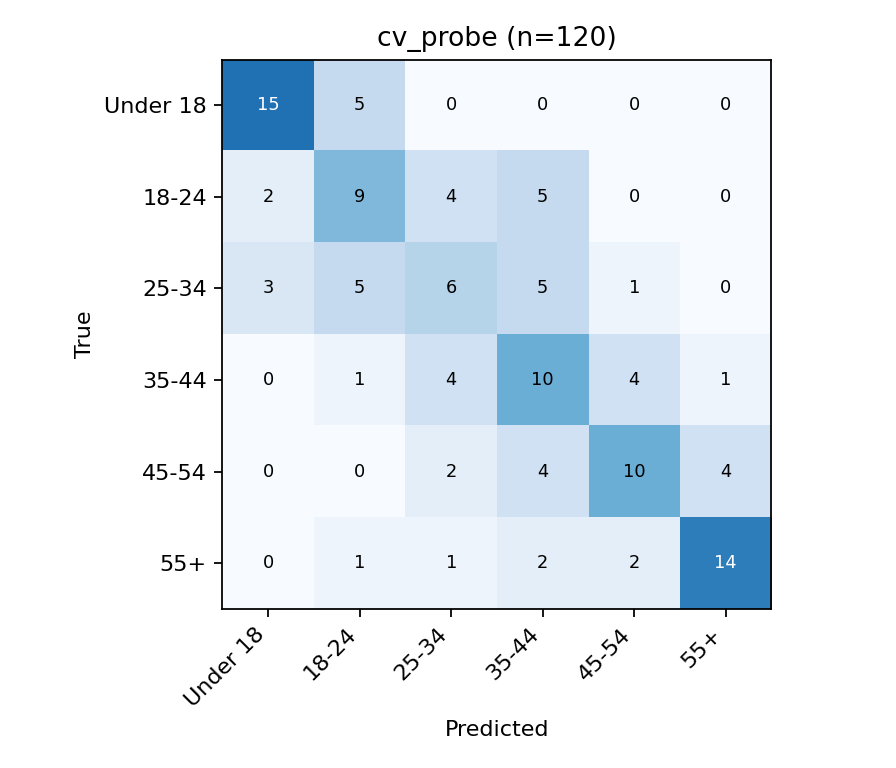

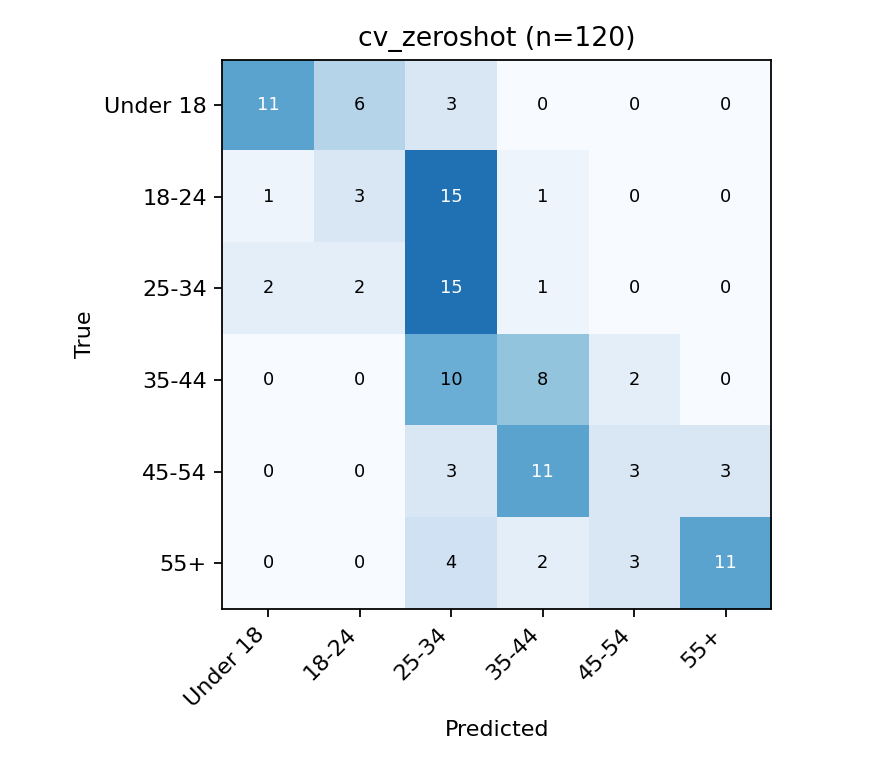

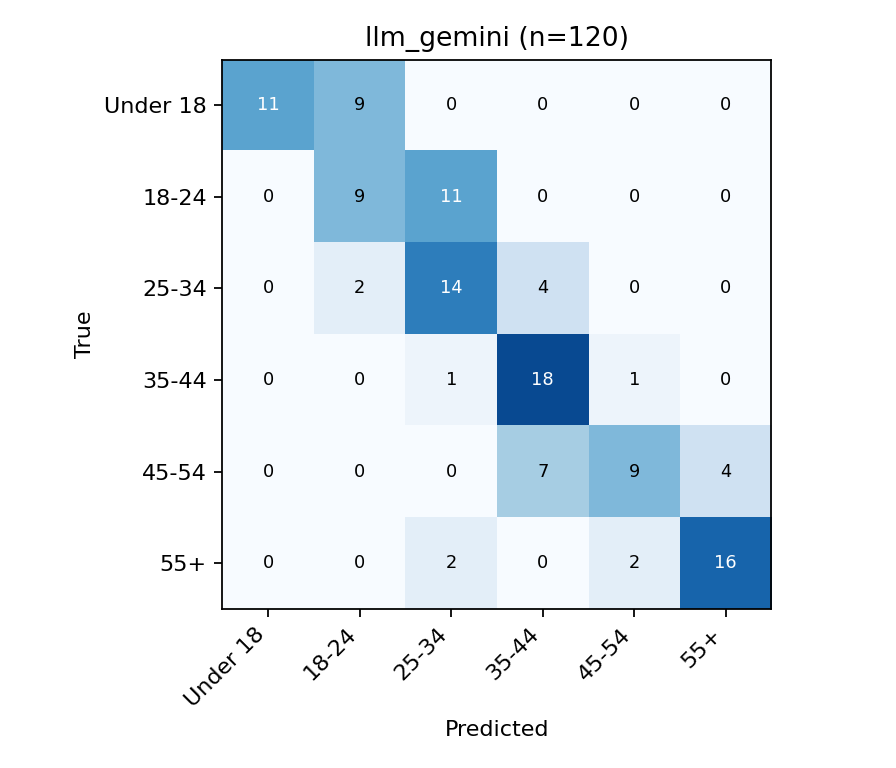

In [39]:
text, approach_names = evaluate_all()
display(Markdown(text))
for n in approach_names:
    display(IPyImage(filename=f"results/confusion_{n}.png", width=420))

## 7. The live API (FastAPI + Docker, deployable to Hugging Face Spaces)
This section **writes the deployable project to `api_repo/`** (one cell per file), copies in the trained probe and the face model, runs the offline tests, checks that serving matches the evaluation, and shows the API logic answering real Wikipedia pages.

What `POST /predict {"url": ...}` does: parse the link (only `*.wikipedia.org/wiki/...`) -> Wikipedia API (live) -> lead image (plus name-matched page images as a fallback) -> Commons photo date -> download the 960 px thumbnail -> **face rule** -> model -> JSON (`person`, `image_used`, `photo_date`, `predicted_age_bracket`, `predicted_age`, `confidence`, ...). If no photo passes the face rule it answers `"status": "no_usable_photo"` with the reason and **does not guess**.
Optional request field `"approach": "cv" | "llm"` (`llm` only if `GEMINI_API_KEY` is set as a server secret; if the LLM call fails the API falls back to `cv` and says so).

In [40]:
for d in ["api_repo/agepred", "api_repo/tests", "api_repo/models", "api_repo/results"]:
    Path(d).mkdir(parents=True, exist_ok=True)

In [41]:
%%writefile api_repo/app.py
"""Live API: POST /predict {"url": "<Wikipedia page link>"} -> age bracket at the time of the photo.

Flow: parse link -> Wikipedia API (live) -> lead image (+ name-matched page images as fallback)
-> Commons photo date -> download 960px thumbnail -> face rule -> model -> JSON.
If no photo passes the face rule the API says so (status "no_usable_photo") instead of guessing.
"""
import logging
import os
import time
from contextlib import asynccontextmanager
from typing import Optional

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel

from agepred import wiki
from agepred.faces import REASON_TEXT, FaceDetector, decode_image, encode_jpeg

log = logging.getLogger("agepred")
logging.basicConfig(level=logging.INFO)

STATE = {"detector": None, "cv": None, "llm": None, "default": "cv"}


def load_models():
    from agepred.cv_model import CVAgeModel
    from agepred.llm import GeminiAgeEstimator
    STATE["detector"] = FaceDetector()
    STATE["cv"] = CVAgeModel()
    try:
        STATE["llm"] = GeminiAgeEstimator.from_env()
    except Exception as e:  # missing SDK etc.: keep the CV approach working
        log.warning("LLM approach disabled: %s", e)
        STATE["llm"] = None
    default = os.environ.get("DEFAULT_APPROACH", "cv").lower()
    STATE["default"] = default if default == "cv" or (default == "llm" and STATE["llm"]) else "cv"
    log.info("Loaded: cv mode=%s, llm=%s, default=%s", STATE["cv"].mode, bool(STATE["llm"]), STATE["default"])


@asynccontextmanager
async def lifespan(app):
    load_models()
    yield


app = FastAPI(title="Age at the time of the photo", version="1.0", lifespan=lifespan)


class PredictRequest(BaseModel):
    url: str
    approach: Optional[str] = None  # "cv" or "llm"; default is set by the server


def _no_photo(person, reasons):
    texts = list(dict.fromkeys(REASON_TEXT.get(r, r) for r in reasons)) or ["the page has no usable image"]
    return {"person": person, "status": "no_usable_photo",
            "message": "No usable photo found: " + "; ".join(texts) + ".",
            "reasons": list(dict.fromkeys(reasons)),
            "image_used": None, "photo_date": None,
            "predicted_age_bracket": None, "predicted_age": None, "confidence": None}


@app.get("/")
def root():
    return {"service": "Age at the time of the photo",
            "usage": 'POST /predict with {"url": "https://en.wikipedia.org/wiki/<Person_Name>"}',
            "docs": "/docs", "health": "/health"}


@app.get("/health")
def health():
    ok = STATE["cv"] is not None and STATE["detector"] is not None
    return {"status": "ok" if ok else "loading",
            "approaches": ["cv"] + (["llm"] if STATE["llm"] else []),
            "default_approach": STATE["default"],
            "cv_mode": STATE["cv"].mode if STATE["cv"] else None}


@app.post("/predict")
def predict(req: PredictRequest):
    t0 = time.time()
    if STATE["cv"] is None or STATE["detector"] is None:
        raise HTTPException(503, "Models are still loading, please retry in a minute")
    approach = (req.approach or STATE["default"]).lower()
    if approach not in ("cv", "llm"):
        raise HTTPException(400, 'approach must be "cv" or "llm"')
    if approach == "llm" and STATE["llm"] is None:
        raise HTTPException(400, 'The "llm" approach is not enabled on this server; use "cv"')

    try:
        host, title = wiki.parse_wikipedia_url(req.url)
        page = wiki.get_page_info(host, title)
    except wiki.BadURL as e:
        raise HTTPException(400, str(e))
    except wiki.PageNotFound as e:
        raise HTTPException(404, str(e))
    except wiki.UpstreamError as e:
        raise HTTPException(502, str(e))

    try:
        cands = wiki.resolve_candidates(host, page)
    except wiki.UpstreamError as e:
        raise HTTPException(502, str(e))
    if not cands:
        return _no_photo(page["title"], ["no_lead_image"])

    reasons, chosen, face = [], None, None
    for c in cands:
        try:
            img = decode_image(wiki.download_image(c["thumb_url"]))
        except wiki.UpstreamError:
            reasons.append("download_failed")
            continue
        if img is None:
            reasons.append("unreadable_image")
            continue
        res = STATE["detector"].detect_main_face(img)
        if res["ok"]:
            chosen, face = c, res
            break
        reasons.append(res["reason"])
    if chosen is None:
        return _no_photo(page["title"], reasons)

    warnings, used = [], approach
    if approach == "llm":
        try:
            pred = STATE["llm"].estimate(encode_jpeg(face["crop"]))
        except Exception as e:  # noqa: BLE001  quota, network, bad answer ...
            log.warning("LLM failed, falling back to CV: %s", e)
            warnings.append("llm_failed_fell_back_to_cv")
            used, pred = "cv", STATE["cv"].predict(face["crop"])
    else:
        pred = STATE["cv"].predict(face["crop"])

    out = {"person": page["title"],
           "status": "ok",
           "image_used": chosen["image_url"],
           "image_page": chosen["file_page"],
           "image_source": chosen["source"],
           "photo_date": chosen["photo_date"],
           "predicted_age_bracket": pred["bracket"],
           "predicted_age": pred["age"],
           "confidence": round(pred["confidence"], 2),
           "approach": used}
    if warnings:
        out["warnings"] = warnings
    log.info("%s -> %s (%s) in %.1fs", page["title"], pred["bracket"], used, time.time() - t0)
    return out

Writing api_repo/app.py


In [42]:
%%writefile api_repo/agepred/__init__.py
"""Shared constants/helpers for the live API.

Keep in sync with pipeline/step3 (face rule) and pipeline/step4 (bracket edges, clamp).
"""
BRACKETS = ["Under 18", "18-24", "25-34", "35-44", "45-54", "55+"]
BRACKET_EDGES = [(0, 18), (18, 25), (25, 35), (35, 45), (45, 55), (55, 100)]  # [lo, hi)


def bracket_of_age(age):
    for name, (lo, hi) in zip(BRACKETS, BRACKET_EDGES):
        if lo <= age < hi:
            return name
    return BRACKETS[-1]


def clamp_age(age, bracket):
    """Make the exact age consistent with the predicted bracket."""
    lo, hi = BRACKET_EDGES[BRACKETS.index(bracket)]
    return int(round(min(max(float(age), lo), hi - 1)))

Writing api_repo/agepred/__init__.py


In [43]:
%%writefile api_repo/agepred/faces.py
"""Face rule used by the API. It mirrors pipeline/step3_faces_and_split.py exactly:
YuNet detector, score >= 0.8, one clear main face (>= 2x as wide as any other face,
>= 60 px), crop with a 30% margin. Photos that fail the rule are reported as unusable.
"""
import os
import threading

import cv2
import numpy as np
import requests

SCORE_MIN = 0.8
MIN_FACE_PX = 60
DOMINANCE = 2.0
MARGIN = 0.3
MODEL_URL = ("https://github.com/opencv/opencv_zoo/raw/main/models/"
             "face_detection_yunet/face_detection_yunet_2023mar.onnx")
DEFAULT_MODEL_PATH = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "models", "yunet.onnx")

REASON_TEXT = {
    "no_lead_image": "the page has no usable image",
    "download_failed": "the image could not be downloaded",
    "unreadable_image": "the image could not be decoded",
    "no_face": "no face was detected in the photo",
    "multiple_faces": "the photo shows several people, so it is unclear which one is the page's subject",
    "face_too_small": "the face in the photo is too small to estimate an age",
}


def decode_image(data: bytes):
    arr = np.frombuffer(data, np.uint8)
    return cv2.imdecode(arr, cv2.IMREAD_COLOR)


def encode_jpeg(img) -> bytes:
    ok, buf = cv2.imencode(".jpg", img)
    return buf.tobytes()


class FaceDetector:
    def __init__(self, model_path=DEFAULT_MODEL_PATH):
        model_path = os.path.abspath(model_path)
        if not os.path.exists(model_path):
            os.makedirs(os.path.dirname(model_path), exist_ok=True)
            r = requests.get(MODEL_URL, timeout=60)
            r.raise_for_status()
            with open(model_path, "wb") as f:
                f.write(r.content)
        if os.path.getsize(model_path) < 100_000:
            raise RuntimeError(f"{model_path} looks wrong (too small). Re-download the YuNet ONNX model.")
        self._det = cv2.FaceDetectorYN.create(model_path, "", (320, 320), SCORE_MIN, 0.3, 5000)
        self._lock = threading.Lock()  # the OpenCV detector keeps state (input size)

    def detect_main_face(self, img):
        """Return dict(ok, reason, crop, n_faces, box, score). crop is a BGR array."""
        h, w = img.shape[:2]
        with self._lock:
            self._det.setInputSize((w, h))
            _, faces = self._det.detect(img)
        faces = [] if faces is None else list(faces)
        real = sorted([f for f in faces if f[14] >= SCORE_MIN], key=lambda f: f[2] * f[3], reverse=True)
        base = {"ok": False, "reason": None, "crop": None, "n_faces": len(faces), "box": None, "score": None}
        if not real:
            return {**base, "reason": "no_face"}
        main = real[0]
        if len(real) > 1 and main[2] < DOMINANCE * real[1][2]:
            return {**base, "reason": "multiple_faces"}
        if main[2] < MIN_FACE_PX or main[3] < MIN_FACE_PX:
            return {**base, "reason": "face_too_small"}
        x, y, fw, fh = [float(v) for v in main[:4]]
        mx, my = fw * MARGIN, fh * MARGIN
        x0, y0 = int(max(0, x - mx)), int(max(0, y - my))
        x1, y1 = int(min(w, x + fw + mx)), int(min(h, y + fh + my))
        crop = img[y0:y1, x0:x1]
        # JPEG round trip so the model sees the same pixels as in training (step 3 saved JPEG crops)
        crop = decode_image(encode_jpeg(crop))
        return {**base, "ok": True, "crop": crop, "box": (x, y, fw, fh), "score": float(main[14])}

Writing api_repo/agepred/faces.py


In [44]:
%%writefile api_repo/agepred/cv_model.py
"""CV approach for the API: pretrained ViT age model + linear probe trained in step 4.

If models/cv_probe.npz exists the probe is used (bracket from logistic regression, exact
age from ridge regression, both stored as plain numpy). Otherwise the pretrained model is
used zero-shot (its 9 age bins mapped to our 6 brackets).
"""
import os
import threading

import numpy as np
from PIL import Image

from . import BRACKETS, BRACKET_EDGES, clamp_age

MODEL_ID = "nateraw/vit-age-classifier"
DEFAULT_PROBE = os.path.join(os.path.dirname(os.path.abspath(__file__)), "..", "models", "cv_probe.npz")


def bin_edges(label):
    if label.lower().startswith("more"):
        return 70.0, 80.0
    a, b = label.split("-")
    return float(a), float(b) + 1.0


def bracket_matrix(bins):
    M = np.zeros((len(bins), len(BRACKETS)))
    for i, (blo, bhi) in enumerate(bins):
        for j, (lo, hi) in enumerate(BRACKET_EDGES):
            M[i, j] = max(0.0, min(bhi, hi) - max(blo, lo)) / (bhi - blo)
    return M


def _softmax(x):
    e = np.exp(x - x.max())
    return e / e.sum()


def probe_predict(emb, probe):
    """emb: (d,) ViT embedding -> dict(bracket, age, confidence). Pure numpy."""
    x = (emb - probe["mean"]) / probe["scale"]
    p = _softmax(probe["clf_w"] @ x + probe["clf_b"])
    k = int(p.argmax())
    bracket = str(probe["classes"][k])
    age = clamp_age(float(probe["reg_w"] @ x + probe["reg_b"]), bracket)
    return {"bracket": bracket, "age": age, "confidence": float(p[k])}


def zero_shot_predict(probs, M, mids):
    bp = probs @ M
    k = int(bp.argmax())
    bracket = BRACKETS[k]
    return {"bracket": bracket, "age": clamp_age(float(probs @ mids), bracket), "confidence": float(bp[k])}


class CVAgeModel:
    def __init__(self, probe_path=DEFAULT_PROBE, model_id=MODEL_ID, device="cpu"):
        import torch
        from transformers import AutoImageProcessor, ViTForImageClassification
        self._torch = torch
        self.device = device
        self.proc = AutoImageProcessor.from_pretrained(model_id)
        self.model = ViTForImageClassification.from_pretrained(model_id).to(device).eval()
        id2label = {int(k): v for k, v in self.model.config.id2label.items()}
        bins = [bin_edges(id2label[i]) for i in range(len(id2label))]
        self.mids = np.array([(a + b) / 2 for a, b in bins])
        self.M = bracket_matrix(bins)
        self.probe = None
        probe_path = os.path.abspath(probe_path)
        if os.path.exists(probe_path):
            z = np.load(probe_path, allow_pickle=True)
            self.probe = {k: z[k] for k in ["mean", "scale", "clf_w", "clf_b", "classes", "reg_w", "reg_b"]}
        self._lock = threading.Lock()

    @property
    def mode(self):
        return "probe" if self.probe is not None else "zeroshot"

    def predict(self, face_bgr):
        torch = self._torch
        img = Image.fromarray(np.ascontiguousarray(face_bgr[:, :, ::-1]))
        with self._lock, torch.no_grad():
            inp = self.proc(images=img, return_tensors="pt")
            h = self.model.vit(pixel_values=inp["pixel_values"].to(self.device)).last_hidden_state[:, 0]
            probs = self.model.classifier(h).softmax(-1)[0].float().cpu().numpy()
            emb = h[0].float().cpu().numpy()
        if self.probe is not None:
            return probe_predict(emb, self.probe)
        return zero_shot_predict(probs, self.M, self.mids)

Writing api_repo/agepred/cv_model.py


In [45]:
%%writefile api_repo/agepred/llm.py
"""Optional LLM approach for the API (Gemini). Enabled only if GEMINI_API_KEY is set as a
secret on the server. The key is read from the environment and never stored in the repo.
Same prompt and parsing as pipeline/step5_llm_model.py."""
import json
import os
import re

from . import BRACKETS, bracket_of_age, clamp_age

PROMPT = (
    "You are an expert at estimating a person's age from a photograph of their face. "
    "Estimate how old the person was when this photo was taken. "
    "Use only what is visible in the image. "
    'Reply with ONLY a JSON object and no other text: '
    '{"age": <integer number of years>, '
    '"bracket": "<exactly one of: Under 18, 18-24, 25-34, 35-44, 45-54, 55+>", '
    '"confidence": <number between 0 and 1>}. '
    "The bracket must contain the age."
)


def parse_answer(raw):
    m = re.search(r"\{.*?\}", raw or "", re.S)
    if not m:
        raise ValueError("LLM answer has no JSON")
    obj = json.loads(m.group(0))
    age = float(obj["age"])
    if not 0 <= age <= 110:
        raise ValueError("age out of range")
    b = str(obj.get("bracket", "")).replace("\u2013", "-").replace("\u2014", "-").strip()
    bracket = b if b in BRACKETS else bracket_of_age(age)
    conf = min(max(float(obj.get("confidence", 0.5)), 0.0), 1.0)
    return {"bracket": bracket, "age": clamp_age(age, bracket), "confidence": conf}


class GeminiAgeEstimator:
    def __init__(self, api_key, model):
        from google import genai
        from google.genai import types
        self._types = types
        self._client = genai.Client(api_key=api_key)
        self.model = model

    @classmethod
    def from_env(cls):
        key = os.environ.get("GEMINI_API_KEY")
        if not key:
            return None
        return cls(key, os.environ.get("GEMINI_MODEL", "gemini-3.1-flash-lite"))

    def estimate(self, jpeg_bytes):
        t = self._types
        resp = self._client.models.generate_content(
            model=self.model,
            contents=[t.Part.from_bytes(data=jpeg_bytes, mime_type="image/jpeg"), PROMPT],
            config=t.GenerateContentConfig(temperature=0.0, response_mime_type="application/json"))
        return parse_answer(resp.text)

Writing api_repo/agepred/llm.py


In [46]:
%%writefile api_repo/agepred/wiki.py
"""Live Wikipedia / Wikimedia Commons client for the API.

The date-parsing block in the middle is generated from pipeline/step2_photo_dates.py so the
live API reads photo dates with exactly the same rules that were used to build the
evaluation data.
"""
import calendar
import datetime as dt
import html
import os
import re
import time
import unicodedata
from urllib.parse import parse_qs, unquote, urlparse

import requests

UA = {"User-Agent": "EchoooAgeAssignment/1.0 (take-home assignment API; candidate Muhammad Shahzad; "
                    + os.environ.get("WIKI_CONTACT", "see GitHub repo") + ")"}
MAX_IMAGE_BYTES = 15_000_000
MAX_FALLBACK_IMAGES = 5


class WikiError(Exception):
    pass


class BadURL(WikiError):
    pass


class PageNotFound(WikiError):
    pass


class UpstreamError(WikiError):
    pass


# ---------------------------------------------------------------- photo dates (generated block)
MONTHS = {m.lower(): i for i, m in enumerate(calendar.month_name) if m}
MONTHS.update({m.lower(): i for i, m in enumerate(calendar.month_abbr) if m})
BAD = re.compile(r"\b(circa|ca|c|about|approx\w*|around|before|after|between|early|late|"
                 r"mid|or|to|and|unknown|undated)\b|[?~/\u2013\u2014]", re.I)


def parse_photo_date(raw):
    """Return (date_lo, date_hi, precision) or (None, None, reason)."""
    if not raw:
        return None, None, "no_photo_date"
    m = re.search(r'datetime="([^"]+)"', raw)
    s = m.group(1) if m else html.unescape(re.sub(r"<[^>]+>", " ", raw))
    s = re.sub(r"\s+", " ", s).strip().rstrip(".")
    # the text says the date is NOT the capture date (upload / scan / publication date)
    if re.search(r"\b(upload\w*|scan\w*|publi\w*|clipping|stamp\w*)\b", s, re.I):
        return None, None, "unparseable_date"
    if (BAD.search(s) or re.search(r"\d{4}s", s)
            or len(re.findall(r"\b\d{4}\b", s)) != 1):
        return None, None, "unparseable_date"

    y = mo = d = None
    if (m := re.match(r"^(\d{4})[-:](\d{2})[-:](\d{2})(?:[T ].*)?$", s)):
        y, mo, d = map(int, m.groups())
    elif (m := re.match(r"^(\d{4})-(\d{2})$", s)):
        y, mo = map(int, m.groups())
    elif (m := re.match(r"^(\d{4})$", s)):
        y = int(m.group(1))
    elif (m := re.match(r"^(\d{1,2}) ([A-Za-z]+),? (\d{4})(?: .*)?$", s)) and m.group(2).lower() in MONTHS:
        d, mo, y = int(m.group(1)), MONTHS[m.group(2).lower()], int(m.group(3))
    elif (m := re.match(r"^([A-Za-z]+) (\d{1,2}),? (\d{4})(?: .*)?$", s)) and m.group(1).lower() in MONTHS:
        mo, d, y = MONTHS[m.group(1).lower()], int(m.group(2)), int(m.group(3))
    elif (m := re.match(r"^([A-Za-z]+),? (\d{4})$", s)) and m.group(1).lower() in MONTHS:
        mo, y = MONTHS[m.group(1).lower()], int(m.group(2))
    else:
        return None, None, "unparseable_date"

    try:
        if d:
            lo = hi = dt.date(y, mo, d); prec = "day"
        elif mo:
            lo = dt.date(y, mo, 1)
            hi = dt.date(y, mo, calendar.monthrange(y, mo)[1]); prec = "month"
        else:
            lo, hi = dt.date(y, 1, 1), dt.date(y, 12, 31); prec = "year"
    except ValueError:
        return None, None, "unparseable_date"
    if y < 1900 or lo > dt.date.today():
        return None, None, "implausible_date"
    return lo, min(hi, dt.date.today()), prec


def clean_raw(raw):
    """Second-pass cleaning for strings like 'Taken on 6 April 2006' or
    '20 September 2025 (according to Exif data)'. Returns None if the date is
    explicitly not a capture date (upload / scan / publication date)."""
    s = html.unescape(re.sub(r"<[^>]+>", " ", str(raw)))
    s = re.sub(r"\s+", " ", s).strip()
    if re.search(r"\([^)]*(upload|scan|publi)", s, re.I):
        return None
    s = re.sub(r"\([^)]*\)", " ", s)
    s = re.sub(r"^(taken|photographed|created)( on)?\s+", "", s, flags=re.I)
    s = re.sub(r",\s*(?=\d{1,2}:\d{2})", " ", s)
    return re.sub(r"\s+", " ", s).strip()




def format_photo_date(lo, hi, prec):
    """'2016-05-03' for day precision, '2016-05' for month, '2016' for year."""
    if prec == "day":
        return lo.isoformat()
    if prec == "month":
        return lo.strftime("%Y-%m")
    return str(lo.year)


# ---------------------------------------------------------------- URL + API helpers
def parse_wikipedia_url(url):
    """Return (host, title). Only https://<lang>.wikipedia.org/wiki/<Title> style links are accepted."""
    u = urlparse((url or "").strip())
    if u.scheme not in ("http", "https") or not u.netloc:
        raise BadURL("Please send a full Wikipedia page link, e.g. https://en.wikipedia.org/wiki/Tom_Hanks")
    host = u.netloc.lower().split(":")[0].replace(".m.", ".")
    if not re.fullmatch(r"[a-z][a-z\-]*\.wikipedia\.org", host):
        raise BadURL("Only wikipedia.org page links are supported")
    if u.path.startswith("/wiki/"):
        title = unquote(u.path[len("/wiki/"):])
    elif u.path.startswith("/w/index.php"):
        title = parse_qs(u.query).get("title", [""])[0]
    else:
        raise BadURL("The link does not look like a Wikipedia article (expected /wiki/<Title>)")
    title = title.replace("_", " ").strip()
    if not title:
        raise BadURL("The link has no page title")
    return host, title


def _get_json(url, params, retries=3, timeout=20):
    params = {**params, "format": "json", "formatversion": 2}
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, headers=UA, timeout=timeout)
            if r.status_code == 200:
                return r.json()
            if r.status_code == 429:
                time.sleep(2 * (attempt + 1))
                continue
        except requests.RequestException:
            pass
        time.sleep(1)
    raise UpstreamError("Wikipedia/Wikimedia did not answer; please try again in a moment")


def get_page_info(host, title):
    d = _get_json(f"https://{host}/w/api.php", {
        "action": "query", "titles": title, "redirects": 1,
        "prop": "pageimages|images", "piprop": "name|original|thumbnail", "pithumbsize": 960,
        "imlimit": 100})
    pages = d.get("query", {}).get("pages", [])
    if not pages or pages[0].get("missing") or pages[0].get("invalid"):
        raise PageNotFound(f"Wikipedia page not found: {title}")
    p = pages[0]
    return {"title": p["title"], "lead_file": p.get("pageimage"),
            "lead_thumb": (p.get("thumbnail") or {}).get("source"),
            "lead_original": (p.get("original") or {}).get("source"),
            "images": [i["title"] for i in p.get("images", [])]}


def _meta_value(md, key):
    v = md.get(key) if isinstance(md, dict) else None
    return v.get("value") if isinstance(v, dict) else None


def commons_info(files):
    """Commons imageinfo for file names: 960px thumbnail url, original url, mime, raw date."""
    out = {}
    files = list(dict.fromkeys(files))[:50]
    if not files:
        return out
    titles = ["File:" + f.replace("_", " ") for f in files]
    d = _get_json("https://commons.wikimedia.org/w/api.php", {
        "action": "query", "titles": "|".join(titles), "redirects": 1, "prop": "imageinfo",
        "iiprop": "url|size|mime|extmetadata", "iiurlwidth": 960,
        "iiextmetadatafilter": "DateTimeOriginal"})
    q = d.get("query", {})
    norm = {n["from"]: n["to"] for n in q.get("normalized", [])}
    redir = {r["from"]: r["to"] for r in q.get("redirects", [])}
    pages = {p["title"]: p for p in q.get("pages", [])}
    for f, t in zip(files, titles):
        t2 = norm.get(t, t)
        p = pages.get(redir.get(t2, t2))
        if not p or p.get("missing") or not p.get("imageinfo"):
            continue
        ii = p["imageinfo"][0]
        out[f] = {"thumb_url": ii.get("thumburl") or ii.get("url"), "image_url": ii.get("url"),
                  "file_page": ii.get("descriptionurl"), "mime": ii.get("mime"),
                  "raw_date": _meta_value(ii.get("extmetadata"), "DateTimeOriginal")}
    return out


# ---------------------------------------------------------------- candidate photos
BAD_WORDS = ("logo", "signature", "autograph", "flag", "map", "icon", "symbol", "coat", "seal", "poster",
             "cover", "album", "banner", "screenshot", "commons-", "wiki", "ambox", "pictogram", "stamp")


def _norm(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9 ]+", " ", s)


def name_matched_files(title, image_titles, exclude=None):
    """Other images on the page whose file name contains part of the person's name."""
    base = re.sub(r"\s*\(.*?\)\s*", " ", title)
    tokens = [t for t in _norm(base).split() if len(t) >= 3]
    ex = _norm(exclude.rsplit(".", 1)[0]) if exclude else None
    out = []
    for t in image_titles:
        fname = t.split(":", 1)[-1]
        low = fname.lower()
        if not low.endswith((".jpg", ".jpeg", ".png")) or any(w in low for w in BAD_WORDS):
            continue
        nf = _norm(fname.rsplit(".", 1)[0])
        if nf == ex:
            continue
        if tokens and any(tok in nf.split() for tok in tokens):
            out.append(fname)
    return out


def resolve_candidates(host, page):
    """Ordered photos to try: the page's lead image first, then name-matched page images."""
    files, meta = [], []
    if page.get("lead_file"):
        files.append(page["lead_file"])
        meta.append({"file": page["lead_file"], "source": "lead_image"})
    for f in name_matched_files(page["title"], page.get("images", []), page.get("lead_file"))[:MAX_FALLBACK_IMAGES]:
        files.append(f)
        meta.append({"file": f, "source": "page_image_name_match"})
    info = commons_info(files) if files else {}
    cands = []
    for m in meta:
        ci = info.get(m["file"])
        if ci and ci["mime"] in ("image/jpeg", "image/png"):
            date = None
            lo, hi, prec = parse_photo_date(ci["raw_date"])
            if lo is None and prec == "unparseable_date":
                cleaned = clean_raw(ci["raw_date"])
                if cleaned:
                    lo, hi, prec = parse_photo_date(cleaned)
            if lo is not None:
                date = format_photo_date(lo, hi, prec)
            cands.append({**m, "thumb_url": ci["thumb_url"], "image_url": ci["image_url"],
                          "file_page": ci["file_page"], "photo_date": date})
        elif m["source"] == "lead_image" and page.get("lead_thumb"):
            # lead image that is not on Commons (e.g. a local fair-use file): no date available
            cands.append({**m, "thumb_url": page["lead_thumb"],
                          "image_url": page.get("lead_original") or page["lead_thumb"],
                          "file_page": None, "photo_date": None})
    return cands


def download_image(url):
    host = urlparse(url).netloc.lower()
    if not host.endswith("wikimedia.org"):
        raise UpstreamError("unexpected image host")
    for attempt in range(3):
        try:
            r = requests.get(url, headers=UA, timeout=30)
            if r.status_code == 200 and r.content:
                if len(r.content) > MAX_IMAGE_BYTES:
                    raise UpstreamError("image too large")
                return r.content
            if r.status_code == 429:
                time.sleep(2 * (attempt + 1))
                continue
        except requests.RequestException:
            pass
        time.sleep(1)
    raise UpstreamError("could not download the image")

Writing api_repo/agepred/wiki.py


In [47]:
%%writefile api_repo/requirements.txt
# Runtime dependencies of the API. torch (CPU build) is installed separately in the Dockerfile.
# After the first successful build run `pip freeze > requirements.lock` and commit it.
fastapi
uvicorn[standard]
requests
numpy
pillow
opencv-python-headless
transformers
google-genai

Writing api_repo/requirements.txt


In [48]:
%%writefile api_repo/Dockerfile
# Hugging Face Spaces (Docker SDK) / any Docker host. CPU only.
FROM python:3.11-slim

RUN apt-get update && apt-get install -y --no-install-recommends libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Spaces runs the container as user 1000
RUN useradd -m -u 1000 user
USER user
ENV HOME=/home/user PATH=/home/user/.local/bin:$PATH \
    HF_HOME=/home/user/.cache/huggingface PYTHONUNBUFFERED=1
WORKDIR $HOME/app

# CPU-only torch first (much smaller than the default CUDA build)
RUN pip install --no-cache-dir torch --index-url https://download.pytorch.org/whl/cpu
COPY --chown=user requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt

# Bake the pretrained age model into the image so the first request is not slow
RUN python -c "from transformers import AutoImageProcessor, ViTForImageClassification as M; \
AutoImageProcessor.from_pretrained('nateraw/vit-age-classifier'); M.from_pretrained('nateraw/vit-age-classifier')"

COPY --chown=user . .

EXPOSE 7860
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "7860"]

Writing api_repo/Dockerfile


In [49]:
%%writefile api_repo/.gitignore
# secrets
.env
*.key
# data and large artefacts (the README explains how to rebuild them)
data/images/
data/faces/
data/cv_features.npz
*.onnx.tmp
# python
__pycache__/
*.pyc
.ipynb_checkpoints/

Writing api_repo/.gitignore


In [50]:
%%writefile api_repo/README.md
---
title: Age at the time of the photo
emoji: 📸
colorFrom: blue
colorTo: indigo
sdk: docker
app_port: 7860
pinned: false
---

# Age at the time of the photo (Echooo AI take-home)

Give the API a Wikipedia page of a person. It finds a usable photo on the page, and returns how old the
person was when the photo was taken (age bracket, plus an estimated exact age).

- **Live API:** `<<FILL: https://<user>-<space>.hf.space>>`  (docs: `/docs`)
- **Candidate:** Muhammad Shahzad, candidate number 0167

```bash
curl -X POST https://<<FILL>>.hf.space/predict -H "Content-Type: application/json" \
     -d '{"url": "https://en.wikipedia.org/wiki/Grace_VanderWaal"}'
```
```json
{"person": "...", "status": "ok", "image_used": "...", "photo_date": "2018-07-22",
 "predicted_age_bracket": "Under 18", "predicted_age": 15, "confidence": 0.71, "approach": "cv"}
```
If the page has no usable photo the API answers `"status": "no_usable_photo"` with the reason, and never guesses.
Optional request field `"approach": "cv" | "llm"` (the `llm` option exists only if an API key is configured on the server).

## 1. Approach in one paragraph
`<<FILL after step 6: 4-5 sentences. Which approach won, by how much, and the most likely reasons.>>`

## 2. Data (collected only from Wikipedia / Wikidata / Wikimedia Commons)
No ready-made or labelled face-age dataset was used for training or testing.

| Step | Count | Note |
|---|---|---|
| Candidate people (Wikidata: human, English Wikipedia article, image, day-precision birth date; 8 occupations x 7 birth decades) | 5,182 | raw query rows 12,279 -> 11,182 after de-duplication -> sampled to about 5,000, balanced by birth decade |
| With a usable labelled photo (Wikipedia lead image, on Commons, photo date known, certain bracket) | 4,613 | dropped: 159 unparseable dates, 146 no lead image, 138 too small, 81 no photo date, 20 ambiguous bracket, 13 bad file type, 8 not on Commons, 4 implausible/impossible dates |
| After face filter (one clear main face) and de-duplication | `<<FILL from step 3>>` | `<<FILL funnel: duplicate_image, no_face, multiple_faces, face_too_small, ...>>` |
| Train / validation / test | `<<FILL>>` | test set is balanced across brackets; split by person (one photo per person) |

**How the true age bracket was computed.** True age = completed years between the person's birth date (Wikidata,
day precision) and the photo date (Commons `DateTimeOriginal`: camera EXIF or the date typed by the uploader).
Dates with day, month or year precision are accepted. For month/year dates we compute the youngest and oldest
possible age and keep the photo only if both fall in the same bracket. Vague dates (circa, before, decades,
ranges) and dates that the text says are upload, scan or publication dates are dropped. Exact age (for MAE) is
used only for day-precision dates.

## 3. Models
| | Model | Notes |
|---|---|---|
| Face detection | YuNet (OpenCV Zoo) | one clear main face required: score >= 0.8, at least 2x as wide as any other face, >= 60 px |
| CV zero-shot | `nateraw/vit-age-classifier` (ViT-base) | **pretrained on the FairFace dataset by its author**; allowed as a pretrained model, but note it for transparency. Its 9 age bins are mapped to our 6 brackets by interval overlap |
| CV + linear probe | same ViT, frozen, plus logistic regression (bracket) and ridge regression (age) trained on our train split | not full fine-tuning; weights stored as numpy in `models/cv_probe.npz` |
| LLM | `<<FILL: Qwen2.5-VL-3B-Instruct (local) and/or Gemini model name>>` | prompted for JSON (age, bracket, confidence); sees only the face crop: no name, no dates, no page text |

## 4. Results (test set, same photos for every approach)
`<<PASTE results/results.md>>`

Confusion matrices: `results/confusion_*.png`. Largest errors: `results/worst_errors_*.csv`.

## 5. Why one approach works better
`<<FILL: use the numbers: per-bracket recall, MAE by bracket, calibration (ECE), paired test.>>`

## 6. What didn't work / shortcuts / limitations (honest list)
- Image download: fetching all ~4,400 thumbnails was far too slow because Wikimedia rate-limits thumbnails at non-standard widths (I had asked for 800 px; standard widths are 20/40/60/120/250/330/500/960/1280/1920/3840) and my first downloader retried silently. Final version (stage 3 of the notebook) downloads a bracket-balanced subset (up to 260 photos per bracket, `<<FILL: n>>` in total), uses original files or 960 px thumbnails and resizes locally. Because of this, the train split is balanced by bracket, not natural.
- Rate limits: the first Wikipedia/Commons run lost 1,951 candidates to HTTP 429; fixed with longer back-off and slower requests.
- Wikidata timeouts: one query cell (actors born in the 1970s) failed repeatedly and was split into 5-year queries.
- Date parsing: the first parser rejected 328 clean dates (formats like "Taken on 6 April 2006"); a second pass recovered 169.
  A later review showed the first parser also accepted dates whose text said "upload"/"scan"; those are now rejected. `<<FILL: how many rows this removed>>`
- Label noise: Commons dates are not guaranteed to be capture dates. Manual check of 30 random photos: `<<FILL: x/30 wrong>>`.
  Accuracy is reported separately for camera-timestamp dates and uploader-typed dates.
- Sampling bias: people are notable (actors, athletes, politicians, ...) with freely licensed photos; sampling inside each
  occupation/decade cell is not random (random ordering times out on Wikidata). We did not measure demographic balance.
- "Under 18" photos are rare, so that bracket has the smallest sample. `<<FILL: numbers>>`
- The pretrained CV model was trained on FairFace (different image style: no stage lighting, mostly frontal portraits).
- The LLM free tier: `<<FILL: what happened with quotas / model availability>>`
- API: photos with several similar-sized faces are refused rather than guessed. If the lead image is unusable the API tries
  other images on the page whose file name contains the person's name (`image_source` field says which was used).
- Free hosting sleeps after inactivity; the first request after a sleep can take about a minute.

## 7. Reproduce
Everything (data collection, labelling, face filter, both approaches, evaluation, API files) is in the notebook
`echooo_age_estimation.ipynb`. Run it top to bottom on a CPU machine; finished stages are skipped when their output files exist.
API locally: `pip install torch --index-url https://download.pytorch.org/whl/cpu && pip install -r requirements.txt && uvicorn app:app --port 7860`.
Tests (no network or GPU needed): `pytest -q tests/test_offline.py`.

## 8. Secrets
No API keys are stored in the repo. The optional LLM approach reads `GEMINI_API_KEY` (and `GEMINI_MODEL`) from the server
environment (Hugging Face Space secrets).

Writing api_repo/README.md


In [51]:
%%writefile api_repo/tests/test_offline.py
"""Offline tests (no internet, no torch needed):  pytest -q tests/test_offline.py

They check the parts that must match between evaluation and serving:
the numpy probe equals the scikit-learn model, the face rule, the date parser, URL parsing,
and the API logic with the network and models replaced by fakes.
"""
import os
import sys

import numpy as np
import pytest

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))

from agepred import BRACKETS, bracket_of_age, clamp_age, wiki  # noqa: E402
from agepred.cv_model import bin_edges, bracket_matrix, probe_predict, zero_shot_predict  # noqa: E402


# ------------------------------------------------------------------ helpers
def test_bracket_and_clamp():
    assert [bracket_of_age(a) for a in (0, 17, 18, 24, 25, 34, 35, 44, 45, 54, 55, 99)] == \
        ["Under 18", "Under 18", "18-24", "18-24", "25-34", "25-34", "35-44", "35-44", "45-54", "45-54", "55+", "55+"]
    assert clamp_age(24.6, "18-24") == 24 and clamp_age(40, "25-34") == 34 and clamp_age(3, "55+") == 55


def test_zero_shot_mapping_rows_sum_to_one():
    labels = ['0-2', '3-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', 'more than 70']
    bins = [bin_edges(l) for l in labels]
    M = bracket_matrix(bins)
    assert np.allclose(M.sum(1), 1)
    probs = np.zeros(9); probs[3] = 1.0                      # model says "20-29"
    out = zero_shot_predict(probs, M, np.array([(a + b) / 2 for a, b in bins]))
    assert out["bracket"] in ("18-24", "25-34") and abs(out["confidence"] - 0.5) < 1e-9


def test_numpy_probe_matches_sklearn(tmp_path):
    from sklearn.linear_model import LogisticRegression, Ridge
    from sklearn.preprocessing import StandardScaler
    rng = np.random.RandomState(0)
    X = rng.randn(600, 32); ages = rng.uniform(5, 80, 600)
    X[:, 0] += ages / 20                                      # signal
    y = np.array([bracket_of_age(a) for a in ages])
    sc = StandardScaler().fit(X); Xs = sc.transform(X)
    clf = LogisticRegression(C=0.5, max_iter=2000, class_weight="balanced").fit(Xs, y)
    reg = Ridge(alpha=10).fit(Xs, ages)
    path = tmp_path / "probe.npz"                              # same keys/format as step 4 writes
    np.savez(path, mean=sc.mean_, scale=sc.scale_, clf_w=clf.coef_, clf_b=clf.intercept_,
             classes=np.array(clf.classes_), reg_w=reg.coef_, reg_b=np.array(reg.intercept_))
    z = np.load(path, allow_pickle=True)
    probe = {k: z[k] for k in ["mean", "scale", "clf_w", "clf_b", "classes", "reg_w", "reg_b"]}
    P = clf.predict_proba(Xs)
    for i in range(50):
        out = probe_predict(X[i], probe)
        assert out["bracket"] == clf.classes_[P[i].argmax()]
        assert abs(out["confidence"] - P[i].max()) < 1e-6
        assert out["age"] == clamp_age(reg.predict(Xs[i:i + 1])[0], out["bracket"])


# ------------------------------------------------------------------ dates / URLs
@pytest.mark.parametrize("raw,expected", [
    ("2016-05-03", "2016-05-03"), ("2013-06-21 19:02:58", "2013-06-21"),
    ("Taken on 6 April 2006", "2006-04-06"), ("30 March 2015, 18:16:28", "2015-03-30"),
    ("20 September 2025 (according to Exif data)", "2025-09-20"),
    ("March 2012", "2012-03"), ("1985", "1985"),
    ("circa 1990", None), ("23 April 2008 (original upload date)", None), ("10/6/2006", None),
    ("1972-1973 season", None), (None, None)])
def test_photo_date_rules(raw, expected):
    lo, hi, prec = wiki.parse_photo_date(raw)
    if lo is None and prec == "unparseable_date":
        c = wiki.clean_raw(raw)
        lo, hi, prec = wiki.parse_photo_date(c) if c else (None, None, "rejected")
    got = wiki.format_photo_date(lo, hi, prec) if lo is not None else None
    assert got == expected


def test_url_parsing():
    assert wiki.parse_wikipedia_url("https://en.wikipedia.org/wiki/Tom_Hanks") == ("en.wikipedia.org", "Tom Hanks")
    assert wiki.parse_wikipedia_url("https://de.m.wikipedia.org/wiki/Angela_Merkel#Leben")[0] == "de.wikipedia.org"
    for bad in ["https://example.com/wiki/X", "nonsense", "https://en.wikipedia.org/", "https://evil.com/?x=en.wikipedia.org/wiki/X"]:
        with pytest.raises(wiki.BadURL):
            wiki.parse_wikipedia_url(bad)


# ------------------------------------------------------------------ face rule with a stubbed detector
def _fake_detector(rows):
    import cv2
    from agepred import faces

    class Stub:
        def setInputSize(self, s): pass
        def detect(self, img): return 1, (np.array(rows, dtype=np.float32) if rows else None)

    d = faces.FaceDetector.__new__(faces.FaceDetector)
    import threading
    d._det, d._lock = Stub(), threading.Lock()
    return d


def _face(x, y, w, h, score=0.95):
    return [x, y, w, h] + [0] * 10 + [score]


def test_face_rule():
    img = np.full((800, 800, 3), 128, np.uint8)
    assert _fake_detector([]).detect_main_face(img)["reason"] == "no_face"
    assert _fake_detector([_face(100, 100, 200, 200, 0.5)]).detect_main_face(img)["reason"] == "no_face"
    assert _fake_detector([_face(100, 100, 200, 200), _face(500, 100, 180, 180)]).detect_main_face(img)["reason"] == "multiple_faces"
    assert _fake_detector([_face(100, 100, 40, 40)]).detect_main_face(img)["reason"] == "face_too_small"
    ok = _fake_detector([_face(100, 100, 200, 200), _face(600, 600, 60, 60)]).detect_main_face(img)   # 200 >= 2*60
    assert ok["ok"] and ok["crop"].shape[0] == 320 and ok["crop"].shape[1] == 320                       # 200 + 2*30%


# ------------------------------------------------------------------ API with fakes
class FakeDetector:
    def __init__(self, result): self.result = result
    def detect_main_face(self, img): return self.result


class FakeCV:
    mode = "probe"
    def predict(self, crop): return {"bracket": "35-44", "age": 38, "confidence": 0.71}


class FakeLLM:
    def __init__(self, fail=False): self.fail = fail
    def estimate(self, jpeg):
        if self.fail: raise RuntimeError("quota")
        return {"bracket": "25-34", "age": 29, "confidence": 0.6}


@pytest.fixture()
def client(monkeypatch):
    import cv2
    from fastapi.testclient import TestClient
    import app as appmod
    ok_crop = np.full((200, 200, 3), 100, np.uint8)
    appmod.STATE.update(detector=FakeDetector({"ok": True, "reason": None, "crop": ok_crop}),
                        cv=FakeCV(), llm=None, default="cv")
    page = {"title": "Jane Doe", "lead_file": "Jane_Doe.jpg", "lead_thumb": None, "lead_original": None, "images": []}
    cand = {"file": "Jane_Doe.jpg", "source": "lead_image", "thumb_url": "https://upload.wikimedia.org/x.jpg",
            "image_url": "https://upload.wikimedia.org/orig.jpg", "file_page": "https://commons.wikimedia.org/wiki/File:Jane_Doe.jpg",
            "photo_date": "2016-05-03"}
    jpg = cv2.imencode(".jpg", np.full((300, 300, 3), 90, np.uint8))[1].tobytes()
    monkeypatch.setattr(appmod.wiki, "get_page_info", lambda host, title: page)
    monkeypatch.setattr(appmod.wiki, "resolve_candidates", lambda host, p: [cand])
    monkeypatch.setattr(appmod.wiki, "download_image", lambda url: jpg)
    return TestClient(appmod.app), appmod


def test_predict_ok(client):
    c, _ = client
    r = c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe"})
    assert r.status_code == 200
    j = r.json()
    assert j["status"] == "ok" and j["person"] == "Jane Doe" and j["photo_date"] == "2016-05-03"
    assert j["predicted_age_bracket"] == "35-44" and j["predicted_age"] == 38 and j["confidence"] == 0.71
    assert j["image_used"].endswith("orig.jpg") and j["approach"] == "cv"


def test_predict_no_usable_photo(client):
    c, app = client
    app.STATE["detector"] = FakeDetector({"ok": False, "reason": "multiple_faces", "crop": None})
    j = c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe"}).json()
    assert j["status"] == "no_usable_photo" and j["predicted_age_bracket"] is None
    assert "several people" in j["message"]


def test_predict_no_image_at_all(client, monkeypatch):
    c, app = client
    monkeypatch.setattr(app.wiki, "resolve_candidates", lambda host, p: [])
    j = c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe"}).json()
    assert j["status"] == "no_usable_photo" and j["reasons"] == ["no_lead_image"]


def test_errors(client, monkeypatch):
    c, app = client
    assert c.post("/predict", json={"url": "https://example.com/wiki/X"}).status_code == 400
    assert c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe", "approach": "llm"}).status_code == 400
    assert c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe", "approach": "xyz"}).status_code == 400
    def missing(host, title): raise app.wiki.PageNotFound("Wikipedia page not found: X")
    monkeypatch.setattr(app.wiki, "get_page_info", missing)
    assert c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Nobody_Here"}).status_code == 404


def test_llm_and_fallback(client):
    c, app = client
    app.STATE["llm"] = FakeLLM()
    j = c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe", "approach": "llm"}).json()
    assert j["approach"] == "llm" and j["predicted_age_bracket"] == "25-34"
    app.STATE["llm"] = FakeLLM(fail=True)
    j = c.post("/predict", json={"url": "https://en.wikipedia.org/wiki/Jane_Doe", "approach": "llm"}).json()
    assert j["approach"] == "cv" and j["warnings"] == ["llm_failed_fell_back_to_cv"]


def test_health_and_root(client):
    c, _ = client
    assert c.get("/health").json()["status"] == "ok"
    assert "usage" in c.get("/").json()


# ------------------------------------------------------------------ Commons returns odd extmetadata shapes
@pytest.mark.parametrize("extmeta,expected", [
    ({"DateTimeOriginal": {"value": "2016-05-03"}}, "2016-05-03"),
    ({}, None), ([], None), (None, None), ({"DateTimeOriginal": []}, None)])
def test_commons_extmetadata_shapes(monkeypatch, extmeta, expected):
    page = {"title": "File:A.jpg", "imageinfo": [{"url": "u", "thumburl": "t", "descriptionurl": "d",
                                                  "mime": "image/jpeg", "extmetadata": extmeta}]}
    monkeypatch.setattr(wiki, "_get_json", lambda url, params, **kw: {"query": {"pages": [page]}})
    assert wiki.commons_info(["A.jpg"])["A.jpg"]["raw_date"] == expected

Writing api_repo/tests/test_offline.py


In [52]:
# Copy the trained probe, the face model and the evaluation outputs into the deployable folder
shutil.copy("models/cv_probe.npz", "api_repo/models/cv_probe.npz")
if not Path(MODEL_PATH).exists():
    ensure_model()                 # downloads the YuNet face detector (stage 3 helper)
shutil.copy(MODEL_PATH, "api_repo/models/yunet.onnx")
for f in glob.glob("results/confusion_*.png") + ["results/results.md", "results/metrics.json"]:
    if Path(f).exists():
        shutil.copy(f, "api_repo/results/")
print(sorted(str(p) for p in Path("api_repo").rglob("*") if p.is_file() and "__pycache__" not in str(p)))

['api_repo/.gitignore', 'api_repo/Dockerfile', 'api_repo/README.md', 'api_repo/agepred/__init__.py', 'api_repo/agepred/cv_model.py', 'api_repo/agepred/faces.py', 'api_repo/agepred/llm.py', 'api_repo/agepred/wiki.py', 'api_repo/app.py', 'api_repo/models/cv_probe.npz', 'api_repo/models/yunet.onnx', 'api_repo/requirements.txt', 'api_repo/results/confusion_cv_probe.png', 'api_repo/results/confusion_cv_zeroshot.png', 'api_repo/results/confusion_full_cv_probe.png', 'api_repo/results/confusion_full_cv_zeroshot.png', 'api_repo/results/confusion_llm_gemini.png', 'api_repo/results/metrics.json', 'api_repo/results/results.md', 'api_repo/tests/test_offline.py']


In [53]:
# Offline tests: probe == scikit-learn model, face rule, date parser, URL parsing, API logic with fakes
import subprocess, sys
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "api_repo/tests/test_offline.py"], capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-500:])

............................                                             [100%]
28 passed in 2.44s
 


In [54]:
# Parity check: the API's code path (decode -> face rule -> crop -> model) must reproduce the evaluation predictions
import sys
sys.path.insert(0, str(Path("api_repo").resolve()))
from agepred.cv_model import CVAgeModel
from agepred.faces import FaceDetector, decode_image

ref = pd.read_csv("results/preds_cv_probe.csv").set_index("qid")
test_ids = [q for q in pd.read_csv("data/final.csv").query("split == 'test'")["qid"]
            if q in ref.index and Path(f"data/images/{q}.jpg").exists()]
assert test_ids, "no test photos in data/images: copy data/images from Colab to run the parity check"
sample = pd.Series(test_ids).sample(min(40, len(test_ids)), random_state=0).tolist()
detector, cv_model = FaceDetector(), CVAgeModel()
print("API model mode:", cv_model.mode, "(must be 'probe' to match results/preds_cv_probe.csv)")
n = same_bracket = close_age = face_disagree = 0
for q in sample:
    res = detector.detect_main_face(decode_image(open(f"data/images/{q}.jpg", "rb").read()))
    if not res["ok"]:
        face_disagree += 1
        print("  face rule disagrees with stage 3 for", q, "->", res["reason"])
        continue
    out, r = cv_model.predict(res["crop"]), ref.loc[q]
    n += 1
    same_bracket += out["bracket"] == r["pred_bracket"]
    close_age += abs(out["age"] - r["pred_age"]) <= 1
print(f"photos: {len(sample)}, face-rule disagreements: {face_disagree}, same bracket: {same_bracket}/{n}, age within 1 year: {close_age}/{n}")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

API model mode: probe (must be 'probe' to match results/preds_cv_probe.csv)
photos: 40, face-rule disagreements: 0, same bracket: 40/40, age within 1 year: 40/40


In [55]:
# The API logic answering live Wikipedia pages (needs internet). Uses the same functions the server calls.
import sys
sys.path.insert(0, str(Path("api_repo").resolve()))
import app as api_app
from fastapi import HTTPException
api_app.load_models()
for url in ["https://en.wikipedia.org/wiki/Tom_Hanks",
            "https://en.wikipedia.org/wiki/Grace_VanderWaal",
            "https://de.wikipedia.org/wiki/Angela_Merkel",
            "https://en.wikipedia.org/wiki/Paris",            # not a person: must not be guessed
            "https://example.com/wiki/Nope"]:                 # invalid link: clear error
    try:
        out = api_app.predict(api_app.PredictRequest(url=url))
        print(json.dumps({k: out.get(k) for k in ["person", "status", "photo_date", "predicted_age_bracket", "predicted_age",
                                                   "confidence", "approach", "image_source", "message"] if out.get(k) is not None}))
    except HTTPException as e:
        print(url, "->", e.status_code, e.detail)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

{"person": "Tom Hanks", "status": "ok", "photo_date": "2023-12-03", "predicted_age_bracket": "55+", "predicted_age": 66, "confidence": 0.99, "approach": "cv", "image_source": "lead_image"}
{"person": "Grace VanderWaal", "status": "ok", "photo_date": "2018-07-22", "predicted_age_bracket": "18-24", "predicted_age": 24, "confidence": 0.43, "approach": "cv", "image_source": "lead_image"}
{"person": "Angela Merkel", "status": "ok", "photo_date": "2023-05-16", "predicted_age_bracket": "55+", "predicted_age": 64, "confidence": 0.97, "approach": "cv", "image_source": "lead_image"}
{"person": "Paris", "status": "no_usable_photo", "message": "No usable photo found: no face was detected in the photo."}
https://example.com/wiki/Nope -> 400 Only wikipedia.org page links are supported


### Run the API as a server and call it
In a terminal (inside `api_repo/`): `uvicorn app:app --port 7860`, then
`curl -X POST http://localhost:7860/predict -H "Content-Type: application/json" -d '{"url": "https://en.wikipedia.org/wiki/Tom_Hanks"}'`
(interactive docs at `http://localhost:7860/docs`).

### Deploy to Hugging Face Spaces (free CPU, Docker)
Create a free account and a **write** token. Check that your account may create a Docker Space (their docs differ on whether compute Spaces need a paid plan). Set `DEPLOY_TO_HF = True` below. The token is typed into a hidden prompt, never stored.

In [59]:
DEPLOY_TO_HF = False
HF_USER, HF_SPACE = "your-hf-username", "echooo-age"
if DEPLOY_TO_HF:
    from huggingface_hub import HfApi
    api = HfApi(token=getpass.getpass("Hugging Face WRITE token (hidden): "))
    repo_id = f"{HF_USER}/{HF_SPACE}"
    api.create_repo(repo_id, repo_type="space", space_sdk="docker", exist_ok=True)
    api.upload_folder(folder_path="api_repo", repo_id=repo_id, repo_type="space",
                      ignore_patterns=["__pycache__/*", "*/__pycache__/*", ".pytest_cache/*"])
    if LLM_BACKEND == "gemini" and input("Also enable the optional LLM approach on the server with your Gemini key? (y/n) ").lower() == "y":
        api.add_space_secret(repo_id, "GEMINI_API_KEY", getpass.getpass("Gemini key (hidden): "))
        api.add_space_variable(repo_id, "GEMINI_MODEL", GEMINI_MODEL)
    print(f"Uploaded. Build logs: https://huggingface.co/spaces/{repo_id}  |  API: https://{HF_USER}-{HF_SPACE}.hf.space/docs")
else:
    print("DEPLOY_TO_HF = False -> nothing uploaded")

DEPLOY_TO_HF = False -> nothing uploaded


## 8. Numbers for the README
Everything the README asks for, collected from the output files: how many photos were started with and used at each step, and the final results.

In [57]:
facts = []
facts.append(f"Candidate people from Wikidata: {len(pd.read_csv('data/candidates.csv'))}")
if Path("data/step2_all.csv").exists():
    s2 = pd.read_csv("data/step2_all.csv")
    facts.append(f"Stage 2 (lead image + Commons date + labels): {int((s2.drop_reason == 'KEPT').sum())} of {len(s2)} kept")
    facts.append("  dropped: " + ", ".join(f"{k} {v}" for k, v in s2.drop_reason.value_counts().items() if k != "KEPT"))
if Path("data/step3_all.csv").exists():
    s3 = pd.read_csv("data/step3_all.csv")
    facts.append(f"Stage 3 (balanced subset downloaded, face filter): {int((s3.drop_reason == 'KEPT').sum())} kept of {len(s3)} labelled photos")
    facts.append("  funnel: " + ", ".join(f"{k} {v}" for k, v in s3.drop_reason.value_counts().items()))
f = pd.read_csv("data/final.csv")
facts.append(f"Manual spot check of 30 labelled photo dates: {globals().get('SPOT_CHECK_WRONG')} wrong (None = not done yet)")
facts.append("Final split sizes: " + ", ".join(f"{k} {v}" for k, v in f.split.value_counts().items()))
facts.append("Date precision of the final photos: " + ", ".join(f"{k} {v}" for k, v in f.date_precision.value_counts().items()))
print("\n".join(facts))
print("\n--- results/results.md (paste into the README, section 4) ---\n")
print(Path("results/results.md").read_text())

Candidate people from Wikidata: 4998
Stage 2 (lead image + Commons date + labels): 4411 of 4998 kept
  dropped: unparseable_date 211, too_small 149, no_lead_image 122, no_photo_date 64, ambiguous_bracket 20, bad_mime 12, not_on_commons 6, implausible_date 2, photo_before_birth 1
Stage 3 (balanced subset downloaded, face filter): 1266 kept of 4411 labelled photos
  funnel: not_selected 2950, KEPT 1266, multiple_faces 95, no_face 59, face_too_small 39, duplicate_image 2
Manual spot check of 30 labelled photo dates: None wrong (None = not done yet)
Final split sizes: train 877, test 270, val 119
Date precision of the final photos: day 1181, year 56, month 29

--- results/results.md (paste into the README, section 4) ---

### A. All approaches, identical photos

Test photos used: **120**

| Approach | Bracket accuracy (95% CI) | Within 1 bracket | Macro-F1 | MAE years (95% CI) | MAE n |
|---|---|---|---|---|---|
| cv_probe | 53.3% (44.2%-62.5%) | 85.8% | 0.534 | 6.35 (5.06-7.74) | 108 |
| 